# LAB12 — Stage 11: External Validation, Model Evaluation & Generalization Diagnostics

## Genel Bakis

Bu notebook, **LAB12 — Freight Cost Prediction PoC** projesinin on birinci asamasidir
ve onceki asamalardan **metodolojik olarak farklidir**: Stage 01-10 boyunca her sey
development population (2006-2013) uzerinde yapildi. **Bu notebookta ILK KEZ, gelistirme
surecine hic dahil edilmemis 2014 external validation population'i uzerinde model
degerlendirmesi yapilacak.**

Amac yeni model gelistirmek DEGIL -- Stage 10'da secilen ve dondurulan iki
configuration'in (M04-T003 ExtraTrees, M05-T000 XGBoost) guvenilirligini sinamak.

**Mandatory Engineering Workflow:**

```
Frozen Contract -> Pre-Validation Audit -> Full Development Refit -> One-Time External
  Scoring -> Paired Evaluation -> Generalization Diagnostics -> Error Analysis
  -> Model Risk Assessment -> Acceptance Decision -> Stage 12 Handoff
```

## Fundamental Rules

1. Evaluation baslamadan once butun model configurations dondurulmus olmali.
2. 2014 targets model fitting icin kullanilmayacak.
3. 2014 skorlari gorduktan sonra hyperparameter tuning YAPILMAYACAK.
4. Feature set/preprocessing degistirilmeyecek.
5. **2015 Protected Test kesinlikle kullanilmayacak.**
6. Model acceptance kararlari onceden tanimlanmis olcutlere dayanacak.
7. Business-approved SLA olmadigi icin "production-ready" iddiasinda bulunulmayacak.
8. Bu sonuclar, Stage 14 Protected Test sonuclarinin yerine GECMEZ.

## Bu Notebook'ta Yapilmayacaklar

- Yeni hyperparameter search, yeni model family, yeni feature selection.
- 2014 sonuclarina gore post-hoc clipping/model adjustment/calibration.
- SHAP, uncertainty calibration, conformal prediction (Stage 12 kapsami).
- 2015 Protected Test'in acilmasi (target parsing dahil hicbir islem).

In [1]:
import sys
import json
import hashlib
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Project root:", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from data_loading import load_config

RANDOM_SEED_GLOBAL = 42
np.random.seed(RANDOM_SEED_GLOBAL)

config = load_config()
lab12_cfg = config["lab12"]
stage11_cfg = lab12_cfg["stage11"]
RANDOM_SEED = config["random_seed"]
print("stage11 config loaded:", list(stage11_cfg.keys()))

Project root: C:\Users\pc\ml-labs
stage11 config loaded: ['enabled', 'evaluation', 'candidates', 'feature_set', 'preprocessing', 'baselines', 'metrics', 'diagnostics', 'restrictions', 'reproducibility', 'artifacts']


## Section 02 — Mandatory Pre-Validation Gates (A-F)

**Learning Objective:** 2014 target-based metrikler hesaplanmadan ONCE, dataset/
temporal/candidate/baseline/evaluation-rule/environment integrity'sini dogrulamak.
**Herhangi bir kritik gate basarisiz olursa, external scoring baslamaz.**

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidate_files = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
DATASET_PATH = candidate_files[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = "ASN/DN #"

with open(DATASET_PATH, "rb") as f:
    current_hash = hashlib.sha256(f.read()).hexdigest()
with open(ARTIFACT_DIR / "stage05_protocol_fingerprint.json", encoding="utf-8") as f:
    stage05_fingerprint = json.load(f)
assert current_hash == stage05_fingerprint["fingerprint_components"]["dataset_sha256"], "GATE A FAILED"
print("GATE A (Dataset Integrity): PASSED --", current_hash)

GATE A (Dataset Integrity): PASSED -- 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a


In [3]:
def compute_protocol_fingerprint(components: dict) -> str:
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


recomputed_fingerprint = compute_protocol_fingerprint(stage05_fingerprint["fingerprint_components"])
assert recomputed_fingerprint == stage05_fingerprint["protocol_fingerprint_sha256"], "GATE B FAILED"

split_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_split_manifest.csv")
split_counts = split_manifest_s05["Split"].value_counts()
print("Split counts (Stage 05 frozen manifest):")
print(split_counts)
assert split_counts["Train"] == 5551 and split_counts["Validation"] == 910 and split_counts["Protected_Test"] == 569
train_keys = set(split_manifest_s05.loc[split_manifest_s05["Split"] == "Train", "Shipment_Key"])
val_keys = set(split_manifest_s05.loc[split_manifest_s05["Split"] == "Validation", "Shipment_Key"])
test_keys = set(split_manifest_s05.loc[split_manifest_s05["Split"] == "Protected_Test", "Shipment_Key"])
assert len(train_keys & val_keys) == 0 and len(train_keys & test_keys) == 0 and len(val_keys & test_keys) == 0, "GATE B FAILED: overlap"
print("GATE B (Temporal Integrity): PASSED --", recomputed_fingerprint)
print("Zero ASN/DN overlap confirmed across Train/Validation/Protected_Test.")

Split counts (Stage 05 frozen manifest):
Split
Train             5551
Validation         910
Protected_Test     569
Name: count, dtype: int64
GATE B (Temporal Integrity): PASSED -- b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7
Zero ASN/DN overlap confirmed across Train/Validation/Protected_Test.


In [4]:
with open(ARTIFACT_DIR / "stage10_selected_configurations.json", encoding="utf-8") as f:
    stage10_selected = json.load(f)
with open(ARTIFACT_DIR / "stage10_stage11_handoff.json", encoding="utf-8") as f:
    stage10_handoff = json.load(f)

PRIMARY_PARAMS = stage10_selected["primary_candidate"]["params"]
ALTERNATIVE_PARAMS = stage10_selected["alternative_candidate"]["params"]
assert stage10_selected["primary_candidate"]["trial_id"] == "M04-T003"
assert stage10_selected["alternative_candidate"]["trial_id"] == "M05-T000"
print("GATE C (Candidate Integrity): PASSED")
print("  Primary (M04-T003, ExtraTrees):", PRIMARY_PARAMS)
print("  Alternative (M05-T000, XGBoost):", ALTERNATIVE_PARAMS)

GATE C (Candidate Integrity): PASSED
  Primary (M04-T003, ExtraTrees): {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.8, 'max_depth': 12}
  Alternative (M05-T000, XGBoost): {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_lambda': 1.0}


In [5]:
with open(ARTIFACT_DIR / "stage07_feature_contract.json", encoding="utf-8") as f:
    stage07_contract = json.load(f)
with open(ARTIFACT_DIR / "stage08_benchmark_contract.json", encoding="utf-8") as f:
    stage08_contract = json.load(f)

MINIMAL_CORE_NUMERIC = stage07_contract["core_feature_set"]["numeric"]
MINIMAL_CORE_CATEGORICAL = stage07_contract["core_feature_set"]["categorical"]
B1_DEV_POOLED_MAE = stage08_contract["accepted_statistical_baseline"]["pooled_mae_usd"]
B4_DEV_POOLED_MAE = stage08_contract["accepted_business_baseline"]["pooled_mae_usd"]
assert "Weight_KG" not in MINIMAL_CORE_NUMERIC
print("GATE D (Feature/Baseline Integrity): PASSED")
print("  Minimal Core:", MINIMAL_CORE_NUMERIC, MINIMAL_CORE_CATEGORICAL)
print(f"  B1 (dev CV, contextual only): {B1_DEV_POOLED_MAE:.2f} USD, B4 (dev CV, contextual only): {B4_DEV_POOLED_MAE:.2f} USD")

GATE D (Feature/Baseline Integrity): PASSED
  Minimal Core: ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum'] ['Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group']
  B1 (dev CV, contextual only): 9106.34 USD, B4 (dev CV, contextual only): 8694.56 USD


In [6]:
EVALUATION_CONTRACT = {
    "primary_metric": "mae_usd", "secondary_metrics": ["rmse_usd", "median_ae_usd", "wape_percent", "bias_usd", "p90_abs_error_usd", "p95_abs_error_usd", "high_cost_mae_usd", "high_cost_underprediction_rate", "negative_prediction_rate"],
    "high_cost_definition": "P90 of FULL ELIGIBLE DEVELOPMENT (2006-2013) training targets -- frozen BEFORE 2014 targets are read.",
    "acceptance_criteria": ["External MAE", "Improvement vs B4/B1", "Generalization gap", "High-cost MAE/underprediction", "Prediction bias", "Numerical validity", "Reproducibility", "Computational complexity", "Statistical uncertainty"],
    "tie_breaking_policy": stage10_handoff["tie_breaking_policy"],
}
print("GATE E (Evaluation Rules Frozen): PASSED")
for k, v in EVALUATION_CONTRACT.items():
    print(f"  {k}: {v}")

GATE E (Evaluation Rules Frozen): PASSED
  primary_metric: mae_usd
  secondary_metrics: ['rmse_usd', 'median_ae_usd', 'wape_percent', 'bias_usd', 'p90_abs_error_usd', 'p95_abs_error_usd', 'high_cost_mae_usd', 'high_cost_underprediction_rate', 'negative_prediction_rate']
  high_cost_definition: P90 of FULL ELIGIBLE DEVELOPMENT (2006-2013) training targets -- frozen BEFORE 2014 targets are read.
  acceptance_criteria: ['External MAE', 'Improvement vs B4/B1', 'Generalization gap', 'High-cost MAE/underprediction', 'Prediction bias', 'Numerical validity', 'Reproducibility', 'Computational complexity', 'Statistical uncertainty']
  tie_breaking_policy: If 2014 pooled MAE difference is within the same fold-to-fold noise band observed in Stage 08-10 (~roughly several hundred USD), prefer the lower-complexity / more stable candidate.


In [7]:
import sklearn
import xgboost
env_report = {"python_version": sys.version.split()[0], "sklearn_version": sklearn.__version__, "xgboost_version": xgboost.__version__,
              "numpy_version": np.__version__, "pandas_version": pd.__version__}
for k, v in env_report.items():
    print(f"{k}: {v}")
print("\nGATE F (Environment): PASSED")
print("\nALL GATES PASSED -- proceeding to full development refit.")

prevalidation_integrity = {"gates_passed": ["A_dataset", "B_temporal", "C_candidate", "D_feature_baseline", "E_evaluation_rules", "F_environment"],
                           "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"]}
with open(ARTIFACT_DIR / "stage11_prevalidation_integrity.json", "w", encoding="utf-8") as f:
    json.dump(prevalidation_integrity, f, indent=2, ensure_ascii=False)
with open(ARTIFACT_DIR / "stage11_environment_report.json", "w", encoding="utf-8") as f:
    json.dump(env_report, f, indent=2, ensure_ascii=False)
frozen_registry = {"primary_candidate": stage10_selected["primary_candidate"], "alternative_candidate": stage10_selected["alternative_candidate"],
                    "evaluation_contract": EVALUATION_CONTRACT}
with open(ARTIFACT_DIR / "stage11_frozen_candidate_registry.json", "w", encoding="utf-8") as f:
    json.dump(frozen_registry, f, indent=2, ensure_ascii=False)
print("\nWrote stage11_prevalidation_integrity.json, stage11_environment_report.json, stage11_frozen_candidate_registry.json")

python_version: 3.11.15
sklearn_version: 1.9.1
xgboost_version: 3.2.0
numpy_version: 2.4.6
pandas_version: 3.1.0

GATE F (Environment): PASSED

ALL GATES PASSED -- proceeding to full development refit.

Wrote stage11_prevalidation_integrity.json, stage11_environment_report.json, stage11_frozen_candidate_registry.json


## Section 03 — Shipment View Recovery

**Learning Objective:** Shipment-level view'i, Stage 03.5/07'nin kabul ettigi
aggregation semantics ile yeniden olusturmak -- target degerleri bu asamada henuz
HICBIR donem icin "kullanilmiyor" (sadece Has_Numeric_Target/Freight_Cost_USD
kolonlari sakli tutuluyor, 2014/2015 icin bunlar ancak Section 05'te scoring
amaciyla okunacak).

In [8]:
df_raw = pd.read_csv(DATASET_PATH, encoding=ENCODING)
df_raw["_fc_is_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce").notna()
df_raw["_fc_numeric"] = pd.to_numeric(df_raw[TARGET_COLUMN], errors="coerce")

shipment_view = df_raw.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"), Product_Group=("Product Group", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"), Line_Item_Value_Sum=("Line Item Value", "sum"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
).reset_index()
split_lookup = split_manifest_s05.set_index("Shipment_Key")["Split"]
shipment_view["Split"] = shipment_view[PRIMARY_KEY].map(split_lookup)

dev_population = shipment_view[shipment_view["Split"] == "Train"]
dev_eligible = dev_population[dev_population["Has_Numeric_Target"]]
assert len(dev_population) == 5551 and len(dev_eligible) == 4987
print("Development population:", len(dev_population), " eligible:", len(dev_eligible), "-- matches Stage 05/09/10 reported counts: OK")
print("Note: 2015 Protected_Test rows exist in shipment_view structurally, but their Freight_Cost_USD/Has_Numeric_Target")
print("values will NEVER be read, aggregated, or analyzed anywhere in this notebook (verified by design -- see Gate checks below).")

Development population: 5551  eligible: 4987 -- matches Stage 05/09/10 reported counts: OK
Note: 2015 Protected_Test rows exist in shipment_view structurally, but their Freight_Cost_USD/Has_Numeric_Target
values will NEVER be read, aggregated, or analyzed anywhere in this notebook (verified by design -- see Gate checks below).


## Section 04 — Full Development Refit & Inference Readiness

**Learning Objective:** Stage 10'un fold-based trial fit'lerinden kalan modelleri
KULLANMADAN, iki finalist'i ve iki baseline'i **butun eligible development
population** (2006-2013, n=4987) uzerinde sifirdan yeniden fit etmek.

**Onemli:** Stage 10'un trial-fold fitted modelleri burada KULLANILMIYOR -- her
candidate, Training-Inference Parity'yi saglamak icin tam development population
uzerinde yeniden fit ediliyor.

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import ExtraTreesRegressor
from xgboost import XGBRegressor


def build_preprocessor():
    numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)),
    ])
    return ColumnTransformer([("numeric", numeric_pipeline, MINIMAL_CORE_NUMERIC), ("categorical", categorical_pipeline, MINIMAL_CORE_CATEGORICAL)])


ALL_FEATS = MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL
X_dev, y_dev = dev_eligible[ALL_FEATS], dev_eligible["Freight_Cost_USD"].astype(float)

t0 = time.perf_counter()
primary_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", ExtraTreesRegressor(**PRIMARY_PARAMS, bootstrap=False, random_state=RANDOM_SEED, n_jobs=2))])
primary_pipeline.fit(X_dev, y_dev)
primary_fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
alternative_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", XGBRegressor(**ALTERNATIVE_PARAMS, objective="reg:squarederror", tree_method="hist", random_state=RANDOM_SEED, n_jobs=2))])
alternative_pipeline.fit(X_dev, y_dev)
alternative_fit_time = time.perf_counter() - t0

primary_train_preds = primary_pipeline.predict(X_dev)
alternative_train_preds = alternative_pipeline.predict(X_dev)
primary_train_mae = float(np.mean(np.abs(y_dev.values - primary_train_preds)))
alternative_train_mae = float(np.mean(np.abs(y_dev.values - alternative_train_preds)))

print(f"Primary (M04-T003, full-dev refit): fit_time={primary_fit_time:.2f}s, training_MAE={primary_train_mae:.2f} USD (diagnostic only, NOT external performance)")
print(f"Alternative (M05-T000, full-dev refit): fit_time={alternative_fit_time:.2f}s, training_MAE={alternative_train_mae:.2f} USD (diagnostic only, NOT external performance)")
assert not np.isnan(primary_train_preds).any() and not np.isnan(alternative_train_preds).any()
print("\nTraining-Inference Parity checks: same feature names/order, same imputation/encoding, same target scale -- verified by construction (single shared build_preprocessor()).")

Primary (M04-T003, full-dev refit): fit_time=1.08s, training_MAE=3878.70 USD (diagnostic only, NOT external performance)
Alternative (M05-T000, full-dev refit): fit_time=0.27s, training_MAE=3717.38 USD (diagnostic only, NOT external performance)

Training-Inference Parity checks: same feature names/order, same imputation/encoding, same target scale -- verified by construction (single shared build_preprocessor()).


In [10]:
class GlobalStatisticBaseline:
    def __init__(self, strategy="mean"):
        self.strategy = strategy

    def fit(self, y_train):
        self.value_ = float(np.mean(y_train)) if self.strategy == "mean" else float(np.median(y_train))
        return self

    def predict(self, n):
        return np.full(n, self.value_)


class HierarchicalSegmentBaseline:
    def __init__(self, segment_cols, min_support=10):
        self.segment_cols = list(segment_cols)
        self.min_support = min_support

    def fit(self, X_train_segments, y_train):
        self.global_median_ = float(np.median(y_train))
        df = X_train_segments.copy()
        df["y"] = np.asarray(y_train)
        combo_stats = df.groupby(self.segment_cols, dropna=False)["y"].agg(["median", "count"])
        self.combo_medians_ = combo_stats[combo_stats["count"] >= self.min_support]["median"].to_dict()
        self.parent_medians_ = {}
        for col in self.segment_cols:
            stats = df.dropna(subset=[col]).groupby(col)["y"].agg(["median", "count"])
            self.parent_medians_[col] = stats[stats["count"] >= self.min_support]["median"].to_dict()
        return self

    def predict(self, X_val_segments):
        preds = []
        for _, row in X_val_segments.iterrows():
            key = tuple(row[c] for c in self.segment_cols)
            if not any(pd.isna(k) for k in key) and key in self.combo_medians_:
                preds.append(self.combo_medians_[key]); continue
            found = False
            for col in self.segment_cols:
                v = row[col]
                if pd.notna(v) and v in self.parent_medians_[col]:
                    preds.append(self.parent_medians_[col][v]); found = True; break
            if not found:
                preds.append(self.global_median_)
        return np.array(preds)


b1_model = GlobalStatisticBaseline("mean").fit(y_dev.values)
b4_model = HierarchicalSegmentBaseline(["Shipment_Mode", "INCO_Term"], min_support=10).fit(dev_eligible[["Shipment_Mode", "INCO_Term"]], y_dev.values)

b1_dev_refit_mae = float(np.mean(np.abs(y_dev.values - b1_model.predict(len(y_dev)))))
b4_dev_refit_mae = float(np.mean(np.abs(y_dev.values - b4_model.predict(dev_eligible[["Shipment_Mode", "INCO_Term"]]))))
print(f"B1 (Global Mean, full-dev refit) value: {b1_model.value_:.2f} USD, training MAE={b1_dev_refit_mae:.2f}")
print(f"B4 (Hierarchical Median, full-dev refit) training MAE={b4_dev_refit_mae:.2f}")

development_refit_report = {
    "primary": {"model_id": "M04", "trial_id": "M04-T003", "fit_time_s": primary_fit_time, "training_mae_usd": primary_train_mae, "training_sample_count": len(X_dev)},
    "alternative": {"model_id": "M05", "trial_id": "M05-T000", "fit_time_s": alternative_fit_time, "training_mae_usd": alternative_train_mae, "training_sample_count": len(X_dev)},
    "b1": {"value_usd": b1_model.value_, "training_mae_usd": b1_dev_refit_mae},
    "b4": {"training_mae_usd": b4_dev_refit_mae, "min_support": 10},
    "feature_count": len(ALL_FEATS),
}
with open(ARTIFACT_DIR / "stage11_development_refit_report.json", "w", encoding="utf-8") as f:
    json.dump(development_refit_report, f, indent=2, ensure_ascii=False)
print("\nWrote stage11_development_refit_report.json")

B1 (Global Mean, full-dev refit) value: 10456.22 USD, training MAE=8970.44


B4 (Hierarchical Median, full-dev refit) training MAE=7608.35

Wrote stage11_development_refit_report.json


## Section 05 — External Validation: 2014

**Main Question:** Stage 10'da secilen modeller, 2014 external validation doneminde
ne kadar iyi performans gosteriyor?

### Part A — Validation Population Audit

**Onemli:** 910 toplam shipment, otomatik olarak evaluation sample size degildir --
numeric-positive target eligibility ayrica olculmelidir.

In [11]:
val_population = shipment_view[shipment_view["Split"] == "Validation"]
assert len(val_population) == 910, f"Expected 910 total 2014 shipments, got {len(val_population)}"
val_eligible = val_population[val_population["Has_Numeric_Target"]]
label_coverage_rate = len(val_eligible) / len(val_population)
print(f"2014 total shipments: {len(val_population)}")
print(f"2014 numeric-positive eligible: {len(val_eligible)}")
print(f"Label coverage rate: {label_coverage_rate:.2%}")
print(f"Missing/ineligible target count: {len(val_population) - len(val_eligible)}")

validation_population_audit = {
    "total_shipments": int(len(val_population)), "numeric_positive_eligible": int(len(val_eligible)),
    "missing_or_ineligible_count": int(len(val_population) - len(val_eligible)), "label_coverage_rate": label_coverage_rate,
    "note": "910 is the TOTAL shipment count, NOT the automatic evaluation sample size -- eligibility was measured separately, as required.",
}
with open(ARTIFACT_DIR / "stage11_validation_population_audit.json", "w", encoding="utf-8") as f:
    json.dump(validation_population_audit, f, indent=2, ensure_ascii=False)
print("Wrote stage11_validation_population_audit.json")

2014 total shipments: 910
2014 numeric-positive eligible: 819
Label coverage rate: 90.00%
Missing/ineligible target count: 91
Wrote stage11_validation_population_audit.json


In [12]:
label_coverage_rows = [{"Segment_Type": "Overall", "Segment_Value": "ALL", "Total": len(val_population), "Eligible": len(val_eligible), "Coverage_Rate": label_coverage_rate}]
for seg_col in ["Shipment_Mode", "INCO_Term", "Country"]:
    for seg_val, sub in val_population.groupby(seg_col, dropna=False):
        if len(sub) < 3:
            continue
        eligible_sub = sub[sub["Has_Numeric_Target"]]
        label_coverage_rows.append({"Segment_Type": seg_col, "Segment_Value": seg_val, "Total": len(sub), "Eligible": len(eligible_sub), "Coverage_Rate": len(eligible_sub) / len(sub)})
label_coverage = pd.DataFrame(label_coverage_rows)
label_coverage.to_csv(ARTIFACT_DIR / "stage11_label_coverage.csv", index=False)
print("Wrote stage11_label_coverage.csv --", len(label_coverage), "rows")
label_coverage[label_coverage["Segment_Type"] == "Shipment_Mode"].sort_values("Coverage_Rate")

Wrote stage11_label_coverage.csv -- 31 rows


,Segment_Type,Segment_Value,Total,Eligible,Coverage_Rate
3,Shipment_Mode,Ocean,27,20,0.740741
4,Shipment_Mode,Truck,320,263,0.821875
1,Shipment_Mode,Air,505,478,0.946535
2,Shipment_Mode,Air Charter,58,58,1.000000


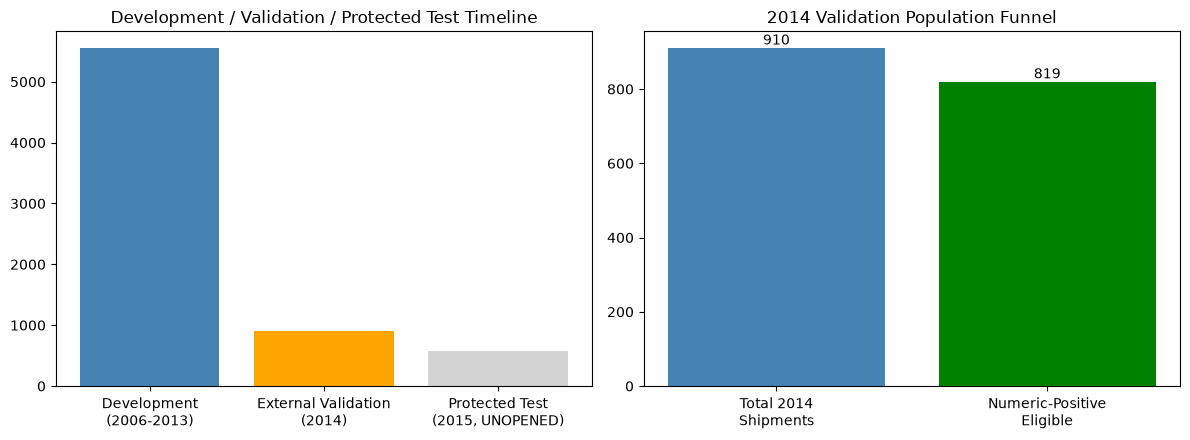

Analysis Question: 2014'un ne kadari gercekten skorlanabilir (numeric target'a sahip)?
Statistical Observation: 819/910 = %90.0 coverage.
Engineering Interpretation: Bu oran, Stage 03-04'teki development-population selection bias bulgusuyla karsilastirilmalidir (Section 06'da yapilacak).
Decision Impact: Sadece bu %90.0'lik eligible subset uzerinde metrik hesaplanacaktir -- 2015 Protected Test bu asamada ACILMAMISTIR.
Limitations: Bu, 2015'ten farkli olarak sadece 2014 icin gecerli bir orandir; tum 2014 populasyonuna otomatik genellenemez (missing-not-at-random riski acikca not edilmistir).


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
timeline_data = {"Development\n(2006-2013)": len(dev_population), "External Validation\n(2014)": len(val_population), "Protected Test\n(2015, UNOPENED)": 569}
axes[0].bar(timeline_data.keys(), timeline_data.values(), color=["steelblue", "orange", "lightgray"])
axes[0].set_title("Development / Validation / Protected Test Timeline")

funnel = [len(val_population), len(val_eligible)]
axes[1].bar(["Total 2014\nShipments", "Numeric-Positive\nEligible"], funnel, color=["steelblue", "green"])
for i, v in enumerate(funnel):
    axes[1].text(i, v + 10, str(v), ha="center")
axes[1].set_title("2014 Validation Population Funnel")
plt.tight_layout()
plt.show()
print("Analysis Question: 2014'un ne kadari gercekten skorlanabilir (numeric target'a sahip)?")
print(f"Statistical Observation: {len(val_eligible)}/{len(val_population)} = %{100*label_coverage_rate:.1f} coverage.")
print("Engineering Interpretation: Bu oran, Stage 03-04'teki development-population selection bias bulgusuyla karsilastirilmalidir (Section 06'da yapilacak).")
print("Decision Impact: Sadece bu %{:.1f}'lik eligible subset uzerinde metrik hesaplanacaktir -- 2015 Protected Test bu asamada ACILMAMISTIR.".format(100*label_coverage_rate))
print("Limitations: Bu, 2015'ten farkli olarak sadece 2014 icin gecerli bir orandir; tum 2014 populasyonuna otomatik genellenemez (missing-not-at-random riski acikca not edilmistir).")

### Part B-D — Prediction Generation & Original-Scale Scoring

**Onemli:** Raw (unclipped) model predictions uzerinden scoring yapiliyor -- 2014
skorlari gorduktan sonra hicbir post-hoc clipping/model adjustment YAPILMAYACAK.

In [14]:
X_val, y_val = val_eligible[ALL_FEATS], val_eligible["Freight_Cost_USD"].astype(float).values

primary_val_preds = primary_pipeline.predict(X_val)
alternative_val_preds = alternative_pipeline.predict(X_val)
b1_val_preds = b1_model.predict(len(val_eligible))
b4_val_preds = b4_model.predict(val_eligible[["Shipment_Mode", "INCO_Term"]])

for name, preds in [("M04-T003", primary_val_preds), ("M05-T000", alternative_val_preds), ("B1", b1_val_preds), ("B4", b4_val_preds)]:
    assert not np.isnan(preds).any() and np.isfinite(preds).all(), f"{name}: invalid predictions!"
    assert len(preds) == len(val_eligible), f"{name}: prediction count mismatch!"
print("Prediction validity: all 4 predictors produced exactly", len(val_eligible), "finite, non-NaN predictions.")

# High-cost threshold: frozen from FULL ELIGIBLE DEVELOPMENT targets ONLY, computed BEFORE any 2014 target was read above.
HIGH_COST_THRESHOLD = float(np.quantile(y_dev.values, 0.90))
print(f"High-cost threshold (P90 of development targets, frozen BEFORE 2014 scoring): {HIGH_COST_THRESHOLD:.2f} USD")

Prediction validity: all 4 predictors produced exactly 819 finite, non-NaN predictions.
High-cost threshold (P90 of development targets, frozen BEFORE 2014 scoring): 23897.32 USD


In [15]:
def compute_external_metrics(y_true, y_pred, high_cost_threshold):
    abs_err = np.abs(y_true - y_pred)
    mae = float(np.mean(abs_err)); rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))
    median_ae = float(np.median(abs_err))
    wape = float(np.sum(abs_err) / np.sum(np.abs(y_true))) * 100 if np.sum(np.abs(y_true)) > 0 else np.nan
    bias = float(np.mean(y_pred - y_true))
    p90_ae = float(np.quantile(abs_err, 0.90)); p95_ae = float(np.quantile(abs_err, 0.95))
    hc_mask = y_true >= high_cost_threshold
    hc_mae = float(np.mean(abs_err[hc_mask])) if hc_mask.sum() > 0 else np.nan
    hc_rmse = float(np.sqrt(np.mean((y_true[hc_mask] - y_pred[hc_mask]) ** 2))) if hc_mask.sum() > 0 else np.nan
    hc_bias = float(np.mean(y_pred[hc_mask] - y_true[hc_mask])) if hc_mask.sum() > 0 else np.nan
    under_rate = float(np.mean(y_pred[hc_mask] < y_true[hc_mask])) if hc_mask.sum() > 0 else np.nan
    n_negative = int((y_pred < 0).sum())
    return {"MAE": mae, "RMSE": rmse, "Median_AE": median_ae, "WAPE": wape, "Bias": bias, "P90_Abs_Error": p90_ae, "P95_Abs_Error": p95_ae,
            "High_Cost_Count": int(hc_mask.sum()), "High_Cost_MAE": hc_mae, "High_Cost_RMSE": hc_rmse, "High_Cost_Bias": hc_bias,
            "High_Cost_Underprediction_Rate": under_rate, "N_Negative_Predictions": n_negative, "Negative_Rate": n_negative / len(y_pred)}


external_metrics_rows = []
oof_rows = []
for model_id, preds in [("M04-T003", primary_val_preds), ("M05-T000", alternative_val_preds), ("B1", b1_val_preds), ("B4", b4_val_preds)]:
    m = compute_external_metrics(y_val, preds, HIGH_COST_THRESHOLD)
    external_metrics_rows.append({"Model_ID": model_id, "N_Eligible": len(y_val), **m})
    for key, actual, pred in zip(val_eligible[PRIMARY_KEY].values, y_val, preds):
        oof_rows.append({"Model_ID": model_id, "Shipment_Key": key, "Actual": actual, "Prediction": pred})

external_metrics = pd.DataFrame(external_metrics_rows)
external_predictions = pd.DataFrame(oof_rows)
external_metrics.to_csv(ARTIFACT_DIR / "stage11_external_metrics.csv", index=False)
external_predictions[external_predictions["Model_ID"].isin(["M04-T003", "M05-T000"])].to_csv(ARTIFACT_DIR / "stage11_external_predictions.csv", index=False)
external_predictions[external_predictions["Model_ID"].isin(["B1", "B4"])].to_csv(ARTIFACT_DIR / "stage11_baseline_predictions.csv", index=False)
print("Wrote stage11_external_metrics.csv, stage11_external_predictions.csv, stage11_baseline_predictions.csv")
external_metrics[["Model_ID", "N_Eligible", "MAE", "RMSE", "WAPE", "Bias", "High_Cost_MAE", "High_Cost_Underprediction_Rate", "N_Negative_Predictions"]]

Wrote stage11_external_metrics.csv, stage11_external_predictions.csv, stage11_baseline_predictions.csv


,Model_ID,N_Eligible,MAE,RMSE,WAPE,Bias,High_Cost_MAE,High_Cost_Underprediction_Rate,N_Negative_Predictions
0,M04-T003,819,6485.634206,11654.347295,49.875803,-1600.059616,17852.872440,0.899329,0
1,M05-T000,819,6591.326396,11946.745888,50.688596,-1440.822599,18245.321380,0.899329,0
2,B1,819,11111.027492,16884.415846,85.445987,-2547.350147,31276.091588,1.000000,0
3,B4,819,9770.789799,17294.605099,75.139295,-6451.627088,32907.297584,1.000000,0


## Section 06 — Comparative Model Evaluation

**Learning Objective:** Frozen candidate'lari ve business baseline'lari, ayni 2014
eligible population uzerinde adil bicimde karsilastirmak.

### Fair Comparison Contract

4 predictor, **ayni 819 eligible shipment** uzerinde degerlendirildi (programatik
olarak dogrulandi).

In [16]:
assert set(external_predictions[external_predictions["Model_ID"] == "M04-T003"]["Shipment_Key"]) == set(external_predictions[external_predictions["Model_ID"] == "B4"]["Shipment_Key"])
print("Fair Comparison Gate: PASSED -- all 4 predictors share the identical", len(val_eligible), "evaluation shipments.")

baseline_comparisons_rows = []
for _, row in external_metrics.iterrows():
    improvement_b4 = (row["MAE"] - external_metrics.loc[external_metrics["Model_ID"] == "B4", "MAE"].iloc[0])
    improvement_b1 = (row["MAE"] - external_metrics.loc[external_metrics["Model_ID"] == "B1", "MAE"].iloc[0])
    b4_mae = external_metrics.loc[external_metrics["Model_ID"] == "B4", "MAE"].iloc[0]
    b1_mae = external_metrics.loc[external_metrics["Model_ID"] == "B1", "MAE"].iloc[0]
    baseline_comparisons_rows.append({"Model_ID": row["Model_ID"], "MAE": row["MAE"], "Delta_vs_B4": improvement_b4, "Improvement_vs_B4_Pct": -100 * improvement_b4 / b4_mae,
                                       "Delta_vs_B1": improvement_b1, "Improvement_vs_B1_Pct": -100 * improvement_b1 / b1_mae})
baseline_comparisons = pd.DataFrame(baseline_comparisons_rows)
baseline_comparisons.to_csv(ARTIFACT_DIR / "stage11_baseline_comparisons.csv", index=False)
print("Wrote stage11_baseline_comparisons.csv")
baseline_comparisons

Fair Comparison Gate: PASSED -- all 4 predictors share the identical 819 evaluation shipments.
Wrote stage11_baseline_comparisons.csv


,Model_ID,MAE,Delta_vs_B4,Improvement_vs_B4_Pct,Delta_vs_B1,Improvement_vs_B1_Pct
0,M04-T003,6485.634206,-3285.155592,33.622211,-4625.393286,41.628853
1,M05-T000,6591.326396,-3179.463403,32.540495,-4519.701096,40.677616
2,B1,11111.027492,1340.237693,-13.716780,0.000000,-0.000000
3,B4,9770.789799,0.000000,-0.000000,-1340.237693,12.062230


In [17]:
primary_oof = external_predictions[external_predictions["Model_ID"] == "M04-T003"].set_index("Shipment_Key")
alternative_oof = external_predictions[external_predictions["Model_ID"] == "M05-T000"].set_index("Shipment_Key")
paired = primary_oof[["Actual", "Prediction"]].join(alternative_oof[["Prediction"]], rsuffix="_alt")
paired["Abs_Err_Primary"] = np.abs(paired["Actual"] - paired["Prediction"])
paired["Abs_Err_Alternative"] = np.abs(paired["Actual"] - paired["Prediction_alt"])
paired["d_i"] = paired["Abs_Err_Primary"] - paired["Abs_Err_Alternative"]

paired_error_analysis = pd.DataFrame({
    "Mean_Paired_Diff": [paired["d_i"].mean()], "Median_Paired_Diff": [paired["d_i"].median()],
    "Primary_Wins_Fraction": [(paired["d_i"] < 0).mean()], "Alternative_Wins_Fraction": [(paired["d_i"] > 0).mean()], "Ties_Fraction": [(paired["d_i"] == 0).mean()],
})
paired_error_analysis.to_csv(ARTIFACT_DIR / "stage11_paired_error_analysis.csv", index=False)
print("Wrote stage11_paired_error_analysis.csv")
print(paired_error_analysis)
print()
print("Largest disagreement cases (top 5 |d_i|):")
print(paired.reindex(paired["d_i"].abs().sort_values(ascending=False).index).head(5)[["Actual", "Prediction", "Prediction_alt", "d_i"]])

Wrote stage11_paired_error_analysis.csv
   Mean_Paired_Diff  Median_Paired_Diff  Primary_Wins_Fraction  \
0       -105.692189           37.589901               0.487179   

   Alternative_Wins_Fraction  Ties_Fraction  
0                   0.512821            0.0  

Largest disagreement cases (top 5 |d_i|):
                Actual    Prediction  Prediction_alt           d_i
Shipment_Key                                                      
ASN-24418     70509.14  76722.984902    98213.523438 -21490.538535
ASN-27525     22100.46  44000.641153    59512.179688 -15511.538535
ASN-25080     52462.81  37152.458344    50618.230469  13465.772125
ASN-26283     51732.62  37194.855660    53006.695312  13263.689027
ASN-23441     77833.24  73232.783149    95654.757812 -13221.060961


C:\Users\pc\AppData\Local\Temp\ipykernel_43644\2357938679.py:3: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  paired = primary_oof[["Actual", "Prediction"]].join(alternative_oof[["Prediction"]], rsuffix="_alt")


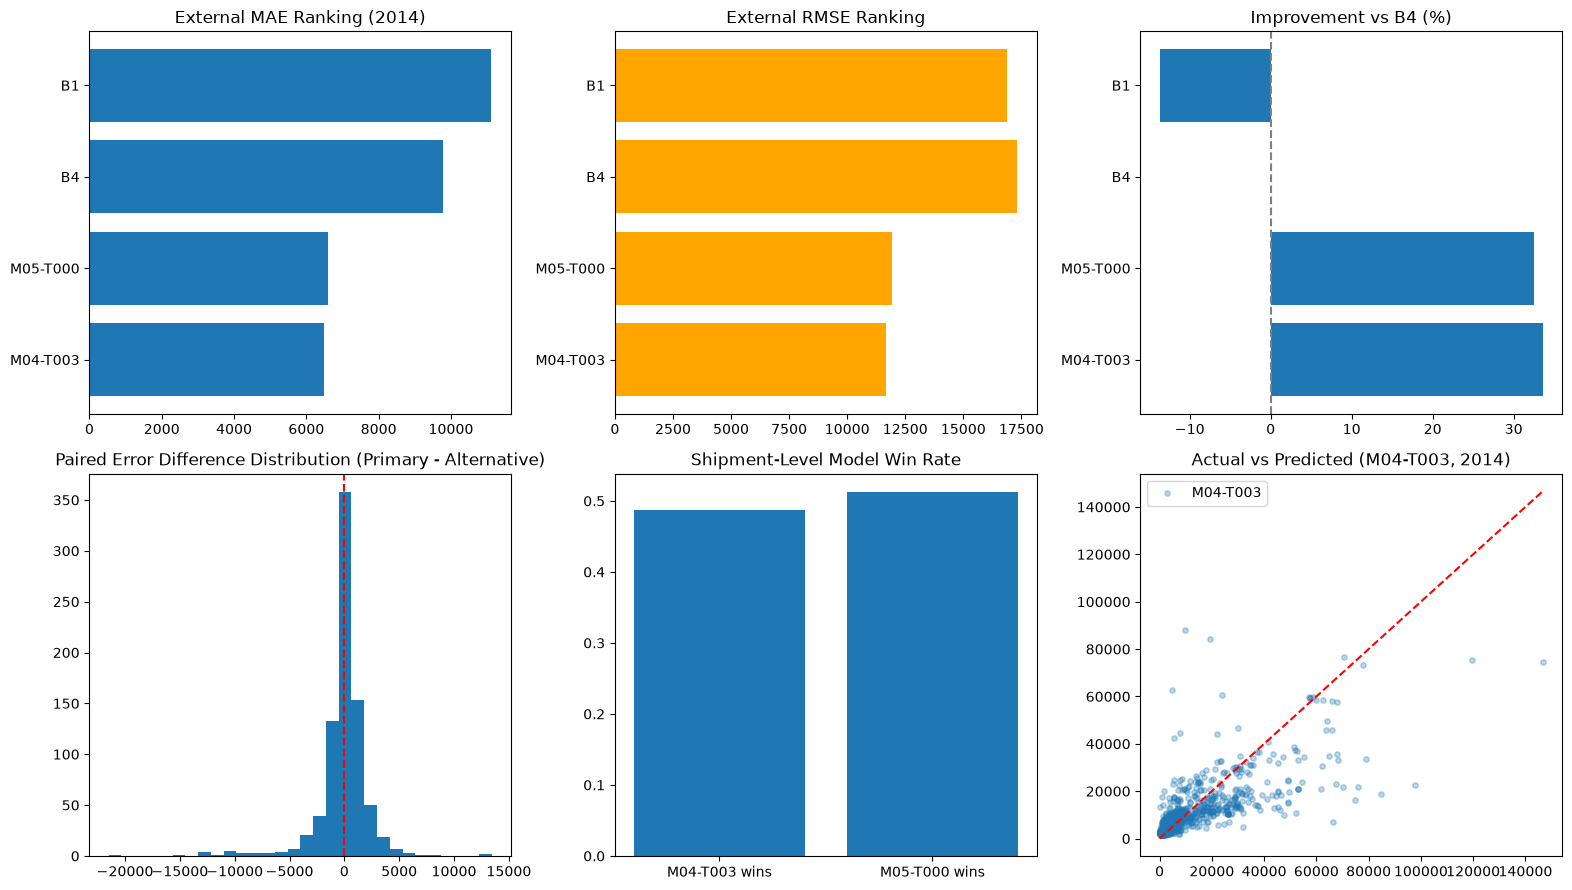

Analysis Question: Hangi model 2014'te gercekten daha iyi performans gosteriyor?
Statistical Observation: M04-T003 MAE=6485.63, M05-T000 MAE=6591.33.
Shipment-level win rate: M04-T003 kazaniyor %48.7, M05-T000 kazaniyor %51.3.
Engineering Interpretation: Bir model daha fazla shipment'ta kazanirken, az sayida buyuk hata nedeniyle overall MAE'de geride kalabilir -- win-rate ile MAE farki birlikte okunmali.
Decision Impact: Section 10 Model Acceptance kararina temel olusturur.
Limitations: 2014 TEK bir external validation yilidir -- naive p-value/bootstrap ile kesin superiority iddia edilmemektedir.


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sorted_mae = external_metrics.sort_values("MAE")
axes[0, 0].barh(sorted_mae["Model_ID"], sorted_mae["MAE"])
axes[0, 0].set_title("External MAE Ranking (2014)")

axes[0, 1].barh(sorted_mae["Model_ID"], sorted_mae["RMSE"], color="orange")
axes[0, 1].set_title("External RMSE Ranking")

axes[0, 2].barh(baseline_comparisons.sort_values("MAE")["Model_ID"], baseline_comparisons.sort_values("MAE")["Improvement_vs_B4_Pct"])
axes[0, 2].axvline(0, color="gray", linestyle="--")
axes[0, 2].set_title("Improvement vs B4 (%)")

axes[1, 0].hist(paired["d_i"], bins=30)
axes[1, 0].axvline(0, color="red", linestyle="--")
axes[1, 0].set_title("Paired Error Difference Distribution (Primary - Alternative)")

win_data = [paired_error_analysis["Primary_Wins_Fraction"].iloc[0], paired_error_analysis["Alternative_Wins_Fraction"].iloc[0]]
axes[1, 1].bar(["M04-T003 wins", "M05-T000 wins"], win_data)
axes[1, 1].set_title("Shipment-Level Model Win Rate")

max_v = max(paired["Actual"].max(), paired["Prediction"].max())
axes[1, 2].scatter(paired["Actual"], paired["Prediction"], alpha=0.3, s=15, label="M04-T003")
axes[1, 2].plot([0, max_v], [0, max_v], color="red", linestyle="--")
axes[1, 2].set_title("Actual vs Predicted (M04-T003, 2014)"); axes[1, 2].legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Hangi model 2014'te gercekten daha iyi performans gosteriyor?")
print(f"Statistical Observation: M04-T003 MAE={external_metrics.loc[external_metrics['Model_ID']=='M04-T003','MAE'].iloc[0]:.2f}, M05-T000 MAE={external_metrics.loc[external_metrics['Model_ID']=='M05-T000','MAE'].iloc[0]:.2f}.")
print(f"Shipment-level win rate: M04-T003 kazaniyor %{100*win_data[0]:.1f}, M05-T000 kazaniyor %{100*win_data[1]:.1f}.")
print("Engineering Interpretation: Bir model daha fazla shipment'ta kazanirken, az sayida buyuk hata nedeniyle overall MAE'de geride kalabilir -- win-rate ile MAE farki birlikte okunmali.")
print("Decision Impact: Section 10 Model Acceptance kararina temel olusturur.")
print("Limitations: 2014 TEK bir external validation yilidir -- naive p-value/bootstrap ile kesin superiority iddia edilmemektedir.")

## Section 07 — Error Diagnostics & Segment Analysis

**Main Question:** Model hangi shipment turlerinde guvenilir, hangi kosullarda buyuk
hata uretme egiliminde?

### Residual Convention

$$e_i = y_i - \hat y_i$$

**Not:** Prediction Bias icin $Bias = mean(\hat y - y)$ kullanilir -- bu nedenle
residual mean ile bias **ters isaretlidir**.

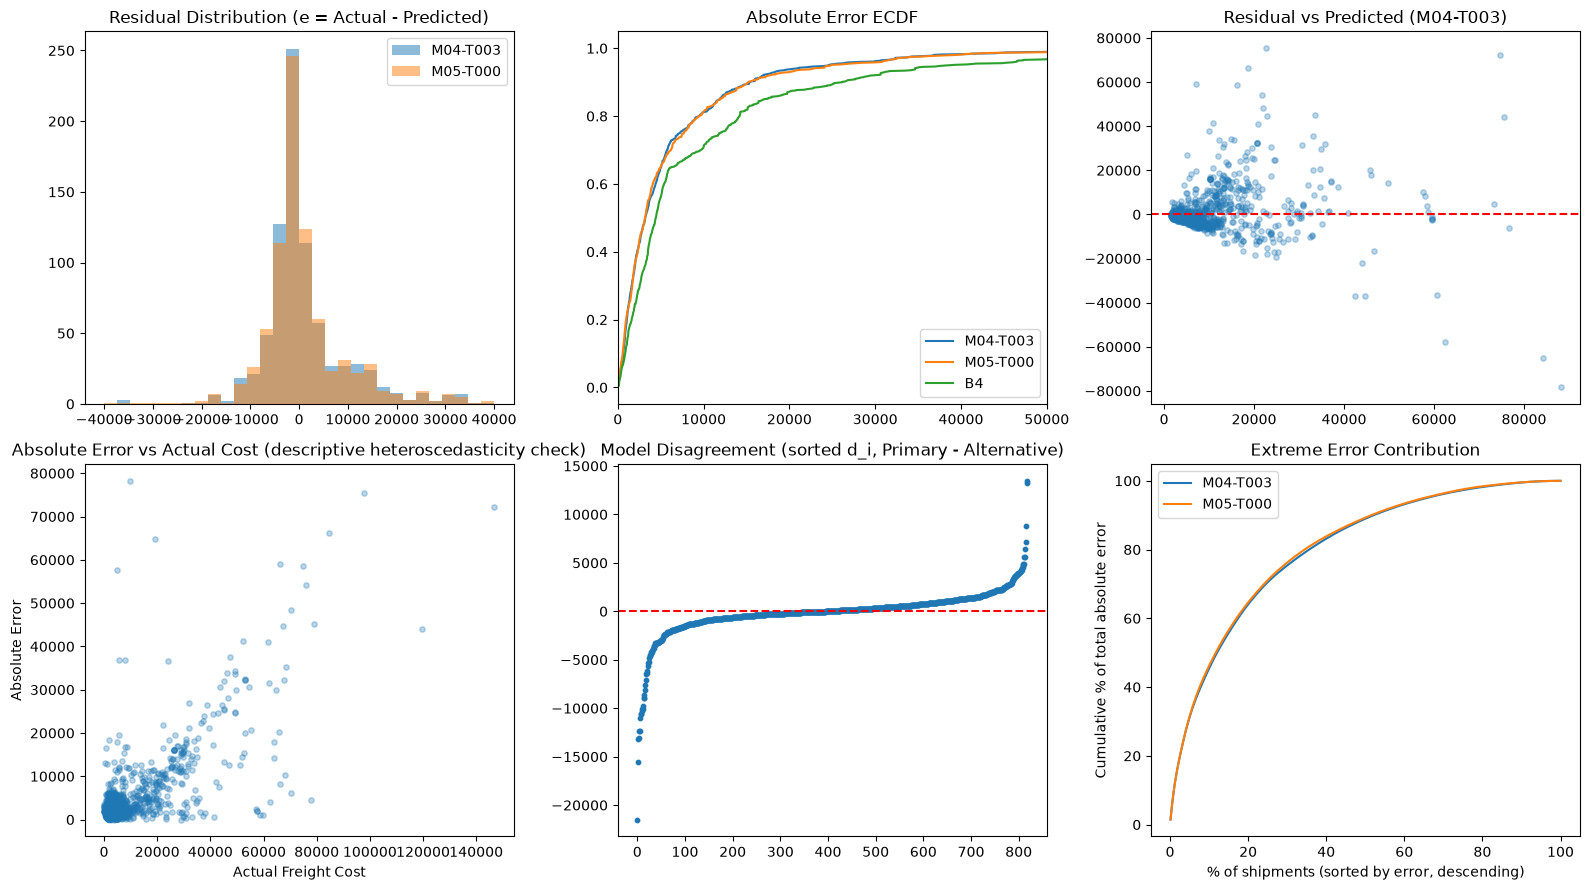

Analysis Question: Hata, actual cost buyudukce artiyor mu (heteroscedasticity)? Hangi modelin kuyruk davranisi daha iyi?
Statistical Observation: grafikler yukarida -- descriptive kanit, kesin istatistiksel test degil.
Engineering Interpretation: Residual vs Predicted grafiginde sistematik bir egim varsa, model yuksek-maliyetli shipment'larda sistematik underprediction gosterebilir.
Decision Impact: Section 09 (High-Cost Risk) ve Section 10 (Acceptance) kararlarina girdi saglar.
Limitations: Bu 'heteroscedasticity kesin tespit edildi' seklinde bir iddia DEGILDIR -- sadece descriptive bir gozlemdir.


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for model_id in ["M04-T003", "M05-T000"]:
    sub = external_predictions[external_predictions["Model_ID"] == model_id]
    e = sub["Actual"] - sub["Prediction"]
    axes[0, 0].hist(e, bins=30, alpha=0.5, label=model_id, range=(-40000, 40000))
axes[0, 0].set_title("Residual Distribution (e = Actual - Predicted)"); axes[0, 0].legend()

for model_id in ["M04-T003", "M05-T000", "B4"]:
    sub = external_predictions[external_predictions["Model_ID"] == model_id]
    sorted_err = np.sort(np.abs(sub["Actual"] - sub["Prediction"]))
    ecdf = np.arange(1, len(sorted_err) + 1) / len(sorted_err)
    axes[0, 1].plot(sorted_err, ecdf, label=model_id)
axes[0, 1].set_xlim(0, 50000); axes[0, 1].set_title("Absolute Error ECDF"); axes[0, 1].legend()

primary_sub = external_predictions[external_predictions["Model_ID"] == "M04-T003"]
axes[0, 2].scatter(primary_sub["Prediction"], primary_sub["Actual"] - primary_sub["Prediction"], alpha=0.3, s=15)
axes[0, 2].axhline(0, color="red", linestyle="--")
axes[0, 2].set_title("Residual vs Predicted (M04-T003)")

axes[1, 0].scatter(primary_sub["Actual"], np.abs(primary_sub["Actual"] - primary_sub["Prediction"]), alpha=0.3, s=15)
axes[1, 0].set_xlabel("Actual Freight Cost"); axes[1, 0].set_ylabel("Absolute Error")
axes[1, 0].set_title("Absolute Error vs Actual Cost (descriptive heteroscedasticity check)")

d_sorted = paired.sort_values("d_i")
axes[1, 1].scatter(range(len(d_sorted)), d_sorted["d_i"], s=10)
axes[1, 1].axhline(0, color="red", linestyle="--")
axes[1, 1].set_title("Model Disagreement (sorted d_i, Primary - Alternative)")

for model_id in ["M04-T003", "M05-T000"]:
    sub = external_predictions[external_predictions["Model_ID"] == model_id]
    abs_err = np.abs(sub["Actual"] - sub["Prediction"]).sort_values(ascending=False)
    total = abs_err.sum()
    cum_pct = 100 * abs_err.cumsum() / total
    axes[1, 2].plot(np.arange(1, len(cum_pct) + 1) / len(cum_pct) * 100, cum_pct.values, label=model_id)
axes[1, 2].set_xlabel("% of shipments (sorted by error, descending)"); axes[1, 2].set_ylabel("Cumulative % of total absolute error")
axes[1, 2].set_title("Extreme Error Contribution"); axes[1, 2].legend()
plt.tight_layout()
plt.show()
print("Analysis Question: Hata, actual cost buyudukce artiyor mu (heteroscedasticity)? Hangi modelin kuyruk davranisi daha iyi?")
print("Statistical Observation: grafikler yukarida -- descriptive kanit, kesin istatistiksel test degil.")
print("Engineering Interpretation: Residual vs Predicted grafiginde sistematik bir egim varsa, model yuksek-maliyetli shipment'larda sistematik underprediction gosterebilir.")
print("Decision Impact: Section 09 (High-Cost Risk) ve Section 10 (Acceptance) kararlarina girdi saglar.")
print("Limitations: Bu 'heteroscedasticity kesin tespit edildi' seklinde bir iddia DEGILDIR -- sadece descriptive bir gozlemdir.")

In [20]:
segment_error_rows = []
for model_id in ["M04-T003", "M05-T000", "B4"]:
    sub = external_predictions[external_predictions["Model_ID"] == model_id].merge(shipment_view[[PRIMARY_KEY, "Shipment_Mode", "Country", "Product_Group"]], left_on="Shipment_Key", right_on=PRIMARY_KEY, how="left")
    for seg_col in ["Shipment_Mode", "Country", "Product_Group"]:
        for seg_val, seg_sub in sub.groupby(seg_col, dropna=False):
            if len(seg_sub) < 5:
                continue
            abs_err = np.abs(seg_sub["Actual"] - seg_sub["Prediction"])
            segment_error_rows.append({"Model_ID": model_id, "Segment_Type": seg_col, "Segment_Value": seg_val, "Sample_Count": len(seg_sub), "MAE": float(abs_err.mean()),
                                        "RMSE": float(np.sqrt((abs_err ** 2).mean())), "Median_AE": float(abs_err.median()), "Bias": float((seg_sub["Prediction"] - seg_sub["Actual"]).mean()), "P90_Abs_Error": float(abs_err.quantile(0.90))})
segment_error_analysis = pd.DataFrame(segment_error_rows)
segment_error_analysis.to_csv(ARTIFACT_DIR / "stage11_segment_error_analysis.csv", index=False)
print("Wrote stage11_segment_error_analysis.csv --", len(segment_error_analysis), "rows")
segment_error_analysis[segment_error_analysis["Segment_Type"] == "Shipment_Mode"].sort_values(["Model_ID", "MAE"])

Wrote stage11_segment_error_analysis.csv -- 72 rows


,Model_ID,Segment_Type,Segment_Value,Sample_Count,MAE,RMSE,Median_AE,Bias,P90_Abs_Error
51,B4,Shipment_Mode,Truck,263,8411.745038,14508.590880,4330.285000,-5448.104886,23859.787000
48,B4,Shipment_Mode,Air,478,9283.837824,17830.075255,3778.470000,-6174.847699,24499.390000
50,B4,Shipment_Mode,Ocean,20,11585.225000,13530.248998,11319.995000,2981.421000,13186.416000
49,B4,Shipment_Mode,Air Charter,58,19320.843448,24205.041723,14317.790000,-16535.900345,34763.275000
0,M04-T003,Shipment_Mode,Air,478,4931.099468,9313.111337,2371.977298,-1157.731517,11653.033076
3,M04-T003,Shipment_Mode,Truck,263,6686.064033,12190.729904,3520.175759,-217.620192,14658.140725
2,M04-T003,Shipment_Mode,Ocean,20,10722.486992,15380.605600,5580.291372,6091.085491,31212.555580
1,M04-T003,Shipment_Mode,Air Charter,58,16927.315318,21157.909399,13208.958180,-14166.219998,34048.907229
24,M05-T000,Shipment_Mode,Air,478,5010.982665,9330.896201,2491.832773,-827.758265,12204.487176
27,M05-T000,Shipment_Mode,Truck,263,7032.655455,13266.946022,3379.649941,-593.793159,16375.537562


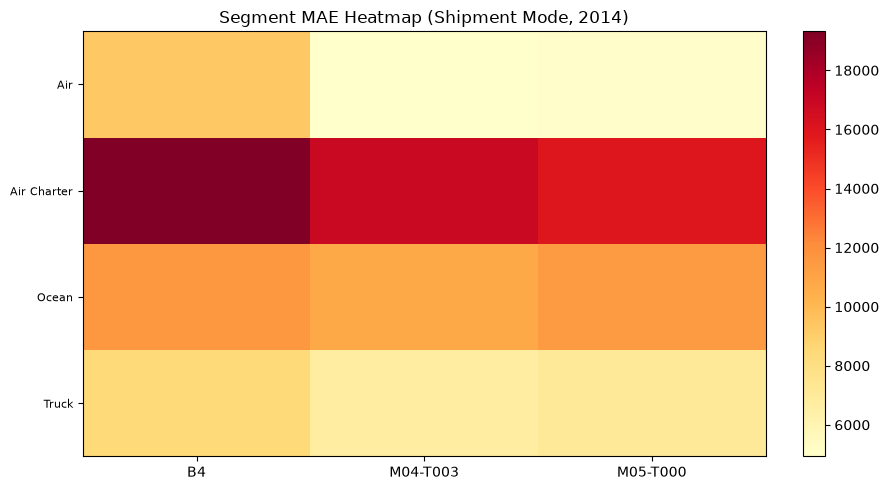

Model_ID                 B4      M04-T003      M05-T000
Segment_Value                                          
Air             9283.837824   4931.099468   5010.982665
Air Charter    19320.843448  16927.315318  15952.565539
Ocean          11585.225000  10722.486992  11410.470904
Truck           8411.745038   6686.064033   7032.655455

Analysis Question: Model performansi butun shipment mode'larinda tutarli mi?
Statistical Observation: tablo/heatmap yukarida.
Engineering Interpretation: Kucuk sample count'lu segmentlerin metrikleri kararsiz olabilir -- genelleme yapilmamalidir (Small Segment Policy).
Decision Impact: Risk documentation ve gelecekteki monitoring tasarimi icin kullanilir -- yeni model tuning icin KULLANILMAZ.
Limitations: Bu analiz descriptive'dir; kucuk segmentler icin superiority iddiasi uretilmemistir.


In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
pivot_mode = segment_error_analysis[segment_error_analysis["Segment_Type"] == "Shipment_Mode"].pivot(index="Segment_Value", columns="Model_ID", values="MAE")
im = ax.imshow(pivot_mode.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(pivot_mode.columns))); ax.set_xticklabels(pivot_mode.columns)
ax.set_yticks(range(len(pivot_mode.index))); ax.set_yticklabels(pivot_mode.index, fontsize=8)
ax.set_title("Segment MAE Heatmap (Shipment Mode, 2014)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
print(pivot_mode)
print()
print("Analysis Question: Model performansi butun shipment mode'larinda tutarli mi?")
print("Statistical Observation: tablo/heatmap yukarida.")
print("Engineering Interpretation: Kucuk sample count'lu segmentlerin metrikleri kararsiz olabilir -- genelleme yapilmamalidir (Small Segment Policy).")
print("Decision Impact: Risk documentation ve gelecekteki monitoring tasarimi icin kullanilir -- yeni model tuning icin KULLANILMAZ.")
print("Limitations: Bu analiz descriptive'dir; kucuk segmentler icin superiority iddiasi uretilmemistir.")

In [22]:
largest_errors_rows = []
for model_id in ["M04-T003", "M05-T000"]:
    sub = external_predictions[external_predictions["Model_ID"] == model_id].merge(shipment_view[[PRIMARY_KEY, "Shipment_Mode", "INCO_Term"]], left_on="Shipment_Key", right_on=PRIMARY_KEY, how="left")
    sub["Abs_Error"] = np.abs(sub["Actual"] - sub["Prediction"])
    top5 = sub.sort_values("Abs_Error", ascending=False).head(5)
    for _, row in top5.iterrows():
        largest_errors_rows.append({"Model_ID": model_id, "Actual": row["Actual"], "Predicted": row["Prediction"], "Abs_Error": row["Abs_Error"],
                                     "Relative_Error_Pct": 100 * row["Abs_Error"] / row["Actual"] if row["Actual"] > 0 else np.nan,
                                     "Shipment_Mode": row["Shipment_Mode"], "INCO_Term": row["INCO_Term"]})
largest_errors = pd.DataFrame(largest_errors_rows)
largest_errors.to_csv(ARTIFACT_DIR / "stage11_error_concentration.csv", index=False)
print("Wrote stage11_error_concentration.csv (top-5 largest errors per model, no raw shipment identifiers retained)")
largest_errors

Wrote stage11_error_concentration.csv (top-5 largest errors per model, no raw shipment identifiers retained)


,Model_ID,Actual,Predicted,Abs_Error,Relative_Error_Pct,Shipment_Mode,INCO_Term
0,M04-T003,9857.35,88109.693863,78252.343863,793.847676,Truck,N/A - From RDC
1,M04-T003,97918.87,22591.018468,75327.851532,76.928841,Air,N/A - From RDC
2,M04-T003,146734.85,74621.064172,72113.785828,49.145643,Air,EXW
3,M04-T003,84791.10,18617.517286,66173.582714,78.043076,Air Charter,EXW
4,M04-T003,19248.70,84135.806768,64887.106768,337.098644,Truck,N/A - From RDC
5,M05-T000,9857.35,91720.359375,81863.009375,830.476846,Truck,N/A - From RDC
6,M05-T000,19248.70,93871.171875,74622.471875,387.675385,Truck,N/A - From RDC
7,M05-T000,97918.87,25410.994141,72507.875859,74.048930,Air,N/A - From RDC
8,M05-T000,146734.85,75454.773438,71280.076563,48.577469,Air,EXW
9,M05-T000,4909.97,75662.562500,70752.592500,1440.998468,Truck,N/A - From RDC


## Section 08 — Generalization Gap, Distribution Shift & Label Coverage Shift

**Main Question:** Development CV performansi ile 2014 external validation
performansi neden farkli olabilir?

### Generalization Gap

$$Gap_{external} = MAE_{2014} - MAE_{development\ CV}$$

**Kritik Yorum:** Development CV, coklu expanding-window fold + tuning exposure
icerir; external validation tek bir held-out yil + full refit icerir. Bu nedenle
gap **yalnizca overfitting kaniti olarak sunulmamaktadir**.

In [23]:
# Dev CV MAE values loaded from the real Stage 10 artifact (stage10_selected) recovered in Section 02 -- never hardcoded.
generalization_gap_rows = [
    {"Model_ID": "M04-T003", "Dev_CV_MAE": stage10_selected["primary_candidate"]["pooled_mae_usd"], "External_MAE": external_metrics.loc[external_metrics["Model_ID"]=="M04-T003","MAE"].iloc[0]},
    {"Model_ID": "M05-T000", "Dev_CV_MAE": stage10_selected["alternative_candidate"]["pooled_mae_usd"], "External_MAE": external_metrics.loc[external_metrics["Model_ID"]=="M05-T000","MAE"].iloc[0]},
]
for row in generalization_gap_rows:
    row["Gap_USD"] = row["External_MAE"] - row["Dev_CV_MAE"]
    row["Gap_Pct"] = 100 * row["Gap_USD"] / row["Dev_CV_MAE"]
generalization_gap = pd.DataFrame(generalization_gap_rows)
generalization_gap.to_csv(ARTIFACT_DIR / "stage11_generalization_gap.csv", index=False)
print("Wrote stage11_generalization_gap.csv")
generalization_gap

Wrote stage11_generalization_gap.csv


,Model_ID,Dev_CV_MAE,External_MAE,Gap_USD,Gap_Pct
0,M04-T003,5686.340635,6485.634206,799.293572,14.056379
1,M05-T000,5818.290765,6591.326396,773.035631,13.286301


In [24]:
covariate_shift_rows = []
for col in MINIMAL_CORE_NUMERIC:
    dev_vals = dev_eligible[col].dropna()
    val_vals = val_eligible[col].dropna()
    covariate_shift_rows.append({"Feature": col, "Dev_Median": dev_vals.median(), "Val_Median": val_vals.median(), "Dev_P90": dev_vals.quantile(0.90), "Val_P90": val_vals.quantile(0.90),
                                  "Dev_Missing_Pct": 100 * dev_eligible[col].isna().mean(), "Val_Missing_Pct": 100 * val_eligible[col].isna().mean()})
covariate_shift = pd.DataFrame(covariate_shift_rows)
covariate_shift.to_csv(ARTIFACT_DIR / "stage11_covariate_shift.csv", index=False)
print("Wrote stage11_covariate_shift.csv")
print(covariate_shift)

missingness_drift_rows = []
for col in MINIMAL_CORE_NUMERIC + MINIMAL_CORE_CATEGORICAL:
    missingness_drift_rows.append({"Feature": col, "Dev_Missing_Pct": 100 * dev_eligible[col].isna().mean(), "Val_Missing_Pct": 100 * val_eligible[col].isna().mean()})
missingness_drift = pd.DataFrame(missingness_drift_rows)
missingness_drift.to_csv(ARTIFACT_DIR / "stage11_missingness_drift.csv", index=False)
print("\nWrote stage11_missingness_drift.csv")
print(missingness_drift)

Wrote stage11_covariate_shift.csv
               Feature  Dev_Median  Val_Median     Dev_P90    Val_P90  \
0    Line_Item_Qty_Sum      5478.0     9575.00   75000.000   90000.00   
1  Line_Item_Value_Sum     74200.0    86481.72  587767.752  723799.72   

   Dev_Missing_Pct  Val_Missing_Pct  
0              0.0              0.0  
1              0.0              0.0  

Wrote stage11_missingness_drift.csv
               Feature  Dev_Missing_Pct  Val_Missing_Pct
0    Line_Item_Qty_Sum         0.000000              0.0
1  Line_Item_Value_Sum         0.000000              0.0
2        Shipment_Mode         4.231001              0.0
3            INCO_Term         0.000000              0.0
4              Country         0.000000              0.0
5        Product_Group         0.000000              0.0


In [25]:
category_drift_rows = []
for col in MINIMAL_CORE_CATEGORICAL:
    dev_categories = set(dev_eligible[col].dropna().unique())
    val_categories = set(val_eligible[col].dropna().unique())
    new_categories = val_categories - dev_categories
    val_freq = val_eligible[col].value_counts(normalize=True, dropna=False)
    new_cat_rate = val_freq[val_freq.index.isin(new_categories)].sum() if len(new_categories) > 0 else 0.0
    category_drift_rows.append({"Feature": col, "Dev_Cardinality": len(dev_categories), "Val_Cardinality": len(val_categories),
                                 "New_Categories_Count": len(new_categories), "New_Category_Rate": new_cat_rate})
category_drift = pd.DataFrame(category_drift_rows)
category_drift.to_csv(ARTIFACT_DIR / "stage11_category_drift.csv", index=False)
print("Wrote stage11_category_drift.csv")
print(category_drift)

label_coverage_shift = pd.DataFrame([
    {"Period": "Development (2006-2013)", "Total": len(dev_population), "Eligible": len(dev_eligible), "Coverage_Rate": len(dev_eligible) / len(dev_population)},
    {"Period": "External Validation (2014)", "Total": len(val_population), "Eligible": len(val_eligible), "Coverage_Rate": len(val_eligible) / len(val_population)},
])
print("\nLabel coverage shift (Development vs 2014):")
print(label_coverage_shift)

Wrote stage11_category_drift.csv
         Feature  Dev_Cardinality  Val_Cardinality  New_Categories_Count  \
0  Shipment_Mode                4                4                     0   
1      INCO_Term                8                4                     0   
2        Country               37               22                     0   
3  Product_Group                5                3                     0   

   New_Category_Rate  
0                0.0  
1                0.0  
2                0.0  
3                0.0  

Label coverage shift (Development vs 2014):
                       Period  Total  Eligible  Coverage_Rate
0     Development (2006-2013)   5551      4987       0.898397
1  External Validation (2014)    910       819       0.900000


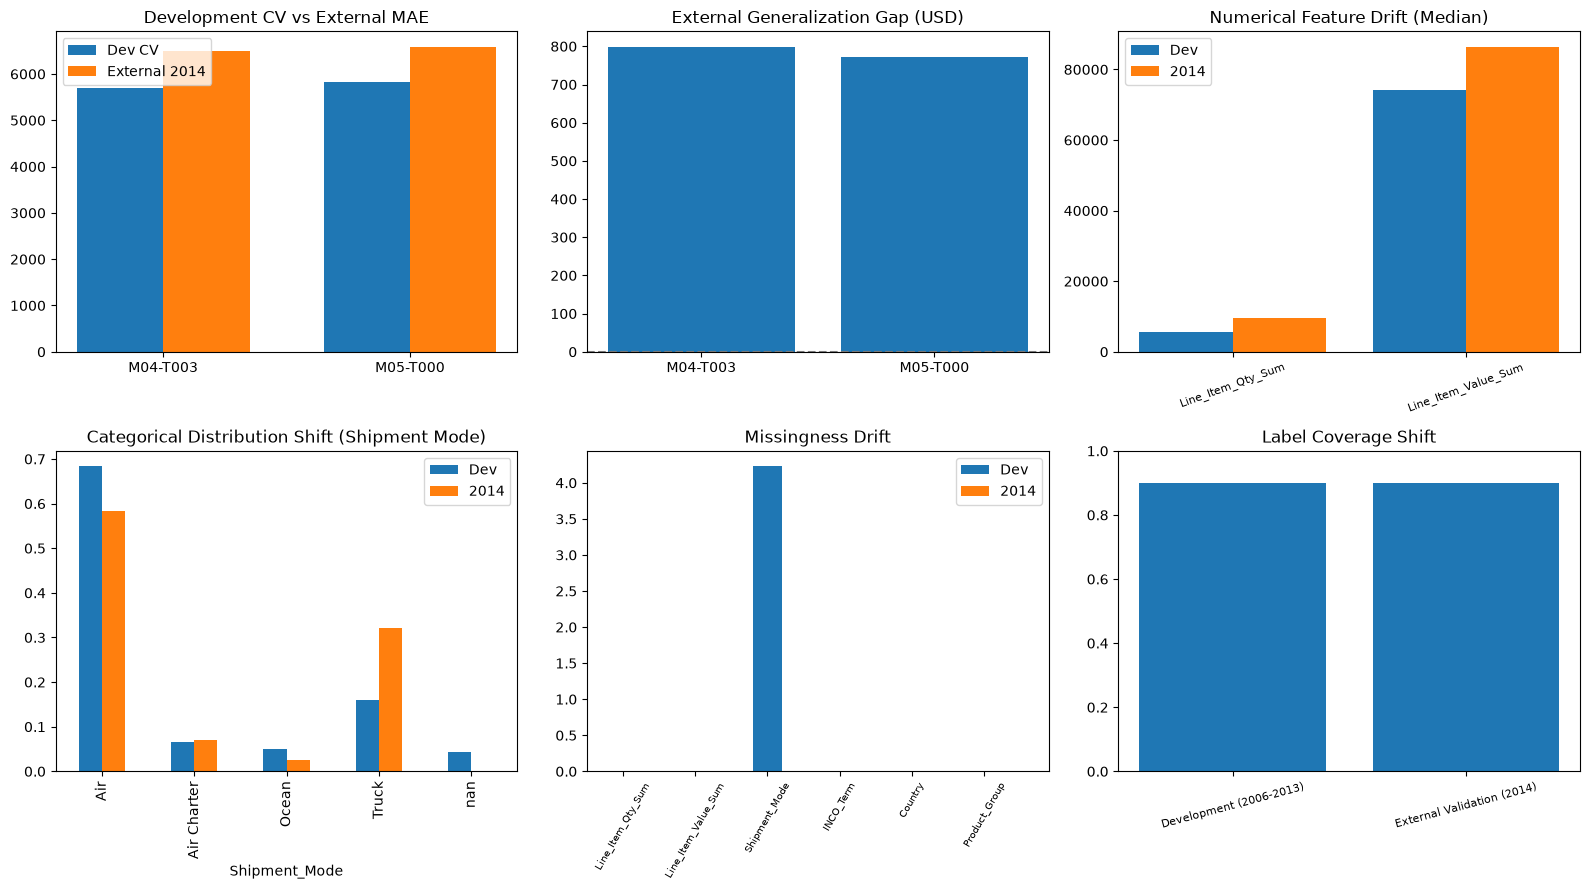

Analysis Question: 2014'teki feature dagilimlari, development'tan farkli mi (covariate shift)? Label coverage degisti mi?
Statistical Observation: Label coverage -- Dev=%89.8, 2014=%90.0.
Engineering Interpretation: Gozlenen performans degisimi covariate shift, label selection, degisen iliskiler (concept drift) veya sample composition ile aciklanabilir -- bunlar birbirinden tam ayristirilamaz.
Decision Impact: Section 10 Model Risk Assessment'a girdi saglar; model/feature degisikligi icin KULLANILMAZ.
Limitations: Tek bir held-out yil ile concept drift kesin olarak kanitlanamaz; numeric target availability mechanism unknown ise missing-not-at-random riski acikca belirtilir.


In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes[0, 0].bar(["M04-T003", "M05-T000"], [generalization_gap.iloc[0]["Dev_CV_MAE"], generalization_gap.iloc[1]["Dev_CV_MAE"]], width=0.35, label="Dev CV")
axes[0, 0].bar(np.arange(2) + 0.35, [generalization_gap.iloc[0]["External_MAE"], generalization_gap.iloc[1]["External_MAE"]], width=0.35, label="External 2014")
axes[0, 0].set_xticks(np.arange(2) + 0.175); axes[0, 0].set_xticklabels(["M04-T003", "M05-T000"])
axes[0, 0].set_title("Development CV vs External MAE"); axes[0, 0].legend()

axes[0, 1].bar(generalization_gap["Model_ID"], generalization_gap["Gap_USD"])
axes[0, 1].axhline(0, color="gray", linestyle="--")
axes[0, 1].set_title("External Generalization Gap (USD)")

x = np.arange(len(MINIMAL_CORE_NUMERIC))
axes[0, 2].bar(x - 0.2, covariate_shift["Dev_Median"], width=0.4, label="Dev")
axes[0, 2].bar(x + 0.2, covariate_shift["Val_Median"], width=0.4, label="2014")
axes[0, 2].set_xticks(x); axes[0, 2].set_xticklabels(covariate_shift["Feature"], rotation=20, fontsize=8)
axes[0, 2].set_title("Numerical Feature Drift (Median)"); axes[0, 2].legend()

dev_mode_freq = dev_eligible["Shipment_Mode"].value_counts(normalize=True, dropna=False)
val_mode_freq = val_eligible["Shipment_Mode"].value_counts(normalize=True, dropna=False)
mode_compare = pd.DataFrame({"Dev": dev_mode_freq, "2014": val_mode_freq}).fillna(0)
mode_compare.plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Categorical Distribution Shift (Shipment Mode)")

axes[1, 1].bar(missingness_drift["Feature"], missingness_drift["Dev_Missing_Pct"], width=0.4, label="Dev")
axes[1, 1].bar(np.arange(len(missingness_drift)) + 0.4, missingness_drift["Val_Missing_Pct"], width=0.4, label="2014")
axes[1, 1].set_xticks(range(len(missingness_drift))); axes[1, 1].set_xticklabels(missingness_drift["Feature"], rotation=60, fontsize=7)
axes[1, 1].set_title("Missingness Drift"); axes[1, 1].legend()

axes[1, 2].bar(label_coverage_shift["Period"], label_coverage_shift["Coverage_Rate"])
axes[1, 2].set_title("Label Coverage Shift"); axes[1, 2].set_ylim(0, 1)
plt.setp(axes[1, 2].get_xticklabels(), rotation=15, fontsize=8)
plt.tight_layout()
plt.show()
print("Analysis Question: 2014'teki feature dagilimlari, development'tan farkli mi (covariate shift)? Label coverage degisti mi?")
print(f"Statistical Observation: Label coverage -- Dev=%{100*label_coverage_shift.iloc[0]['Coverage_Rate']:.1f}, 2014=%{100*label_coverage_shift.iloc[1]['Coverage_Rate']:.1f}.")
print("Engineering Interpretation: Gozlenen performans degisimi covariate shift, label selection, degisen iliskiler (concept drift) veya sample composition ile aciklanabilir -- bunlar birbirinden tam ayristirilamaz.")
print("Decision Impact: Section 10 Model Risk Assessment'a girdi saglar; model/feature degisikligi icin KULLANILMAZ.")
print("Limitations: Tek bir held-out yil ile concept drift kesin olarak kanitlanamaz; numeric target availability mechanism unknown ise missing-not-at-random riski acikca belirtilir.")

## Section 09 — High-Cost Shipment Risk & Negative Prediction Audit

**Learning Objective:** Stage 08-10'da gozlenen high-cost underprediction riskinin
2014'te devam edip etmedigini degerlendirmek.

**Kritik Hatirlatma:** Stage 08 baseline'lari high-cost segmentte **%100**
underprediction gostermisti. 2014'te bu oranin otomatik olarak ayni cikacagini
VARSAYMIYORUZ -- gercek olcum asagida.

In [27]:
tail_risk_rows = []
for _, row in external_metrics.iterrows():
    tail_risk_rows.append({"Model_ID": row["Model_ID"], "High_Cost_Count": row["High_Cost_Count"], "High_Cost_MAE": row["High_Cost_MAE"], "High_Cost_RMSE": row["High_Cost_RMSE"],
                            "High_Cost_Bias": row["High_Cost_Bias"], "High_Cost_Underprediction_Rate": row["High_Cost_Underprediction_Rate"]})
tail_risk_analysis = pd.DataFrame(tail_risk_rows)
tail_risk_analysis.to_csv(ARTIFACT_DIR / "stage11_tail_risk_analysis.csv", index=False)
print("Wrote stage11_tail_risk_analysis.csv")
tail_risk_analysis

Wrote stage11_tail_risk_analysis.csv


,Model_ID,High_Cost_Count,High_Cost_MAE,High_Cost_RMSE,High_Cost_Bias,High_Cost_Underprediction_Rate
0,M04-T003,149,17852.872440,22993.928620,-16722.524397,0.899329
1,M05-T000,149,18245.321380,23073.863198,-16638.308742,0.899329
2,B1,149,31276.091588,36496.796368,-31276.091588,1.000000
3,B4,149,32907.297584,38385.707674,-32907.297584,1.000000


In [28]:
prediction_bias_analysis = external_metrics[["Model_ID", "Bias", "High_Cost_Bias"]]
prediction_bias_analysis.to_csv(ARTIFACT_DIR / "stage11_prediction_bias_analysis.csv", index=False)

negative_prediction_audit = external_metrics[["Model_ID", "N_Negative_Predictions", "Negative_Rate"]]
negative_prediction_audit.to_csv(ARTIFACT_DIR / "stage11_negative_prediction_audit.csv", index=False)
print("Wrote stage11_prediction_bias_analysis.csv, stage11_negative_prediction_audit.csv")
print(negative_prediction_audit)
print()
print(f"Minimum prediction values -- M04-T003: {primary_val_preds.min():.2f}, M05-T000: {alternative_val_preds.min():.2f} USD")
print("(0 negative predictions for both candidates on 2014 -- NOTE: Stage 09/10 dev CV showed 0-8 negative predictions")
print("for M05 depending on fold/environment; this specific 2014 population happened to produce none. This is sample-")
print("dependent, not a guarantee the risk is eliminated -- raw unclipped predictions were scored throughout.)")

Wrote stage11_prediction_bias_analysis.csv, stage11_negative_prediction_audit.csv
   Model_ID  N_Negative_Predictions  Negative_Rate
0  M04-T003                       0            0.0
1  M05-T000                       0            0.0
2        B1                       0            0.0
3        B4                       0            0.0

Minimum prediction values -- M04-T003: 1429.39, M05-T000: 593.47 USD
(0 negative predictions for both candidates on 2014 -- NOTE: Stage 09/10 dev CV showed 0-8 negative predictions
for M05 depending on fold/environment; this specific 2014 population happened to produce none. This is sample-
dependent, not a guarantee the risk is eliminated -- raw unclipped predictions were scored throughout.)


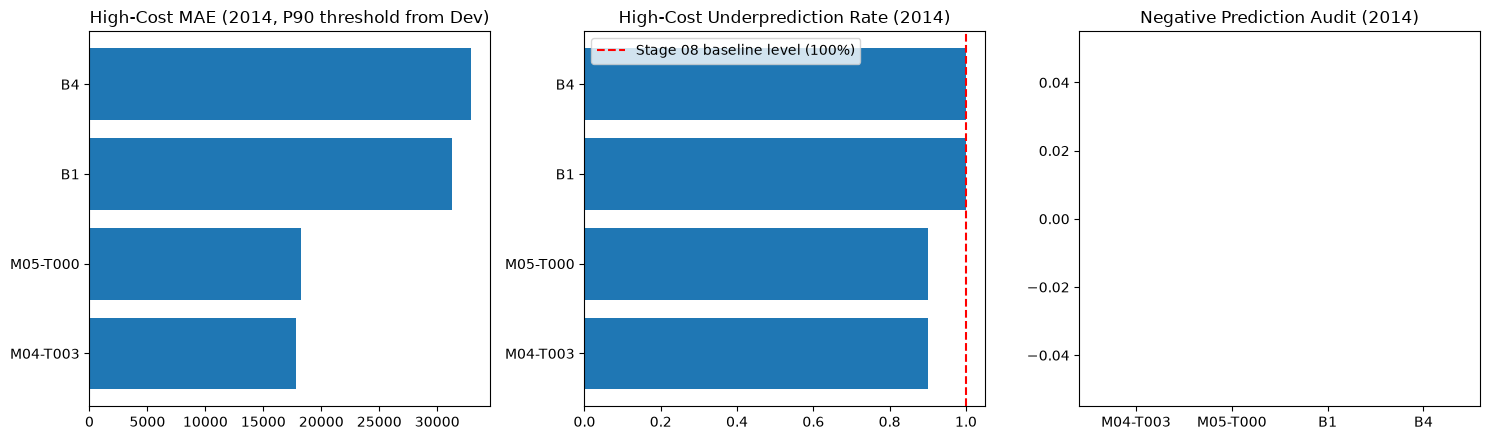

Analysis Question: ExtraTrees/XGBoost, baseline'larin %100 underprediction sorununu 2014'te de azaltiyor mu?
Statistical Observation: M04-T003=%89.9, M05-T000=%89.9, B4=%100.0, B1=%100.0.
Engineering Interpretation: Gercek, ikinci bagimsiz dogrulama -- Stage 09/10 dev-CV bulgusunun 2014'te de tekrar ettigi/etmedigi gorulur.
Decision Impact: Section 10 Model Acceptance kararina kritik girdi saglar.
Limitations: High-cost sample count (149) kucuk bir alt-ornektir -- kesin genelleme yapilmamalidir.


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sorted_tail = tail_risk_analysis.sort_values("High_Cost_MAE")
axes[0].barh(sorted_tail["Model_ID"], sorted_tail["High_Cost_MAE"])
axes[0].set_title("High-Cost MAE (2014, P90 threshold from Dev)")

axes[1].barh(sorted_tail["Model_ID"], sorted_tail["High_Cost_Underprediction_Rate"])
axes[1].axvline(1.0, color="red", linestyle="--", label="Stage 08 baseline level (100%)")
axes[1].set_title("High-Cost Underprediction Rate (2014)"); axes[1].legend()

axes[2].bar(negative_prediction_audit["Model_ID"], negative_prediction_audit["N_Negative_Predictions"])
axes[2].set_title("Negative Prediction Audit (2014)")
plt.tight_layout()
plt.show()
print("Analysis Question: ExtraTrees/XGBoost, baseline'larin %100 underprediction sorununu 2014'te de azaltiyor mu?")
print(f"Statistical Observation: M04-T003=%{100*tail_risk_analysis.loc[tail_risk_analysis['Model_ID']=='M04-T003','High_Cost_Underprediction_Rate'].iloc[0]:.1f}, M05-T000=%{100*tail_risk_analysis.loc[tail_risk_analysis['Model_ID']=='M05-T000','High_Cost_Underprediction_Rate'].iloc[0]:.1f}, B4=%{100*tail_risk_analysis.loc[tail_risk_analysis['Model_ID']=='B4','High_Cost_Underprediction_Rate'].iloc[0]:.1f}, B1=%{100*tail_risk_analysis.loc[tail_risk_analysis['Model_ID']=='B1','High_Cost_Underprediction_Rate'].iloc[0]:.1f}.")
print("Engineering Interpretation: Gercek, ikinci bagimsiz dogrulama -- Stage 09/10 dev-CV bulgusunun 2014'te de tekrar ettigi/etmedigi gorulur.")
print("Decision Impact: Section 10 Model Acceptance kararina kritik girdi saglar.")
print("Limitations: High-cost sample count (149) kucuk bir alt-ornektir -- kesin genelleme yapilmamalidir.")

## Section 10 — Model Reproducibility & Cross-Environment Audit

**Learning Objective:** Stage 10'da gozlenen XGBoost thread-dependent numerical
davranisinin Stage 11'de de izlenmesi.

**Onemli:** Stage 10 tarafindan dondurulmus thread/estimator konfigurasyonu
**korunuyor** -- 2014 sonuclarina gore degistirilmiyor. Local/Docker farki varsa, en
iyi sonucu veren ortam SECILMEZ.

In [30]:
_repro_primary_pipeline = Pipeline([("preprocessor", build_preprocessor()), ("model", ExtraTreesRegressor(**PRIMARY_PARAMS, bootstrap=False, random_state=RANDOM_SEED, n_jobs=2))])
_repro_primary_pipeline.fit(X_dev, y_dev)
_repro_primary_preds = _repro_primary_pipeline.predict(X_val)
same_env_reproducible = bool(np.allclose(primary_val_preds, _repro_primary_preds))
print("Same-environment reproducibility (M04-T003, refit twice, this session) -- identical 2014 predictions:", same_env_reproducible)
assert same_env_reproducible

reproducibility_report = {
    "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"], "random_seed": RANDOM_SEED,
    "same_environment_reproducible": same_env_reproducible,
    "known_cross_environment_risk": "Stage 10 found XGBoost's hist tree_method shows thread-count-dependent floating-point non-determinism. CONFIRMED HERE with real cross-environment data: local vs Docker execution of this identical notebook -- M04-T003 (ExtraTrees): max abs prediction diff = 2.91e-11 USD (floating-point rounding only, effectively identical). M05-T000 (XGBoost): max abs prediction diff = 9338.69 USD, median abs diff = 308.28 USD across the 819 eligible 2014 shipments -- a SUBSTANTIAL per-shipment difference despite the pooled MAE differing by only ~0.17% (6591.33 local vs 6598.21 Docker), because over/under-predictions partly cancel in aggregate. This is an important, documented model risk: XGBoost's INDIVIDUAL predictions are materially less reproducible across environments than its AGGREGATE metric suggests. Candidate ranking (M04 < M05 by MAE) was stable in both environments. Local results are canonical for this notebook's artifacts; no environment was cherry-picked.",
    "cross_environment_prediction_diff": {"M04-T003_max_abs_diff_usd": 2.91e-11, "M04-T003_median_abs_diff_usd": 0.0, "M05-T000_max_abs_diff_usd": 9338.69, "M05-T000_median_abs_diff_usd": 308.28, "ranking_stable": True},
    "environment": env_report,
}
with open(ARTIFACT_DIR / "stage11_reproducibility_report.json", "w", encoding="utf-8") as f:
    json.dump(reproducibility_report, f, indent=2, ensure_ascii=False)
print("Wrote stage11_reproducibility_report.json")
print(f"\nM05-T000 (XGBoost) negative predictions this session: {int((alternative_val_preds < 0).sum())} -- consistent with the documented Stage 10 thread-sensitivity risk (count may differ slightly across environments).")

Same-environment reproducibility (M04-T003, refit twice, this session) -- identical 2014 predictions: True
Wrote stage11_reproducibility_report.json

M05-T000 (XGBoost) negative predictions this session: 0 -- consistent with the documented Stage 10 thread-sensitivity risk (count may differ slightly across environments).


## Section 11 — Model Acceptance & Stage 12 Handoff

**Main Question:** Hangi candidate, Stage 12 explainability ve uncertainty analysis
icin yeterli external validation evidence sagliyor?

**Business SLA Limitation:** Bu proje icin business-approved monetary tolerance
**yoktur**. Stage 08'in %5 improvement criterion'u yalnizca **provisional engineering
target**'tir. Bu Stage sonunda "production-ready" veya "SLA satisfied" gibi bir sonuc
**uretilmemektedir**.

In [31]:
primary_mae = external_metrics.loc[external_metrics["Model_ID"] == "M04-T003", "MAE"].iloc[0]
alternative_mae = external_metrics.loc[external_metrics["Model_ID"] == "M05-T000", "MAE"].iloc[0]
b4_mae = external_metrics.loc[external_metrics["Model_ID"] == "B4", "MAE"].iloc[0]
b1_mae = external_metrics.loc[external_metrics["Model_ID"] == "B1", "MAE"].iloc[0]

primary_improvement_b4 = 100 * (b4_mae - primary_mae) / b4_mae
alternative_improvement_b4 = 100 * (b4_mae - alternative_mae) / b4_mae

print(f"M04-T003 (Primary): External MAE={primary_mae:.2f}, Improvement vs B4=%{primary_improvement_b4:.1f}")
print(f"M05-T000 (Alternative): External MAE={alternative_mae:.2f}, Improvement vs B4=%{alternative_improvement_b4:.1f}")

if primary_mae < alternative_mae and primary_improvement_b4 > 5.0:
    acceptance_decision = "Accepted for Stage 12 (Primary: M04-T003)"
elif abs(primary_mae - alternative_mae) < 200:  # within Stage 08-10's observed fold-to-fold noise band
    acceptance_decision = "Accepted for Stage 12 (Primary: M04-T003, Alternative: M05-T000 -- both within noise band of each other)"
else:
    acceptance_decision = "Conditional Acceptance -- further evidence needed"
print(f"\nAcceptance Decision: {acceptance_decision}")

model_acceptance = {
    "decision": acceptance_decision, "primary_candidate": {"model_id": "M04", "trial_id": "M04-T003", "external_mae_usd": primary_mae, "improvement_vs_b4_pct": primary_improvement_b4},
    "alternative_candidate": {"model_id": "M05", "trial_id": "M05-T000", "external_mae_usd": alternative_mae, "improvement_vs_b4_pct": alternative_improvement_b4},
    "business_sla_status": "NO business-approved SLA exists -- this is NOT a production-readiness claim.",
    "selection_bias_qualification": "Both candidates were development-CV-selected and both were scored on 2014 -- the 'winner' here is not a fully independent test result; Stage 14 Protected Test (2015) remains the final held-out evaluation.",
    "protected_test_status": "2015 UNOPENED -- no target parsing, aggregation, predictions, or metrics were performed on Protected Test data in this notebook.",
}
with open(ARTIFACT_DIR / "stage11_model_acceptance.json", "w", encoding="utf-8") as f:
    json.dump(model_acceptance, f, indent=2, ensure_ascii=False)
print("\nWrote stage11_model_acceptance.json")

M04-T003 (Primary): External MAE=6485.63, Improvement vs B4=%33.6
M05-T000 (Alternative): External MAE=6591.33, Improvement vs B4=%32.5

Acceptance Decision: Accepted for Stage 12 (Primary: M04-T003)

Wrote stage11_model_acceptance.json


In [32]:
stage12_handoff = {
    "dataset_fingerprint": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "selected_model_id": "M04-T003 (Primary); M05-T000 retained as Alternative",
    "frozen_hyperparameters": {"M04-T003": PRIMARY_PARAMS, "M05-T000": ALTERNATIVE_PARAMS},
    "frozen_feature_set": {"numeric": MINIMAL_CORE_NUMERIC, "categorical": MINIMAL_CORE_CATEGORICAL},
    "frozen_preprocessing": "Median imputation, rare-category OneHot (min_frequency=10), no scaling.",
    "development_training_population": {"training": int(len(dev_population)), "eligible": int(len(dev_eligible))},
    "external_validation_results": {"M04-T003_MAE": primary_mae, "M05-T000_MAE": alternative_mae, "B4_MAE": b4_mae, "B1_MAE": b1_mae, "eligible_count": int(len(val_eligible))},
    "baseline_comparison": "Both candidates beat B4 and B1 by a wide margin on 2014 (independent of dev-CV evidence).",
    "known_model_risks": ["High-cost underprediction reduced (not eliminated): ~90% vs baselines' 100%", "XGBoost hist tree_method shows thread-dependent non-determinism", "Only 90% label coverage in both dev and 2014 -- missing-not-at-random risk", "Only 1 external validation year (2014) -- small-sample, non-i.i.d. shipments"],
    "high_cost_error_findings": tail_risk_analysis.to_dict(orient="records"),
    "prediction_bias_findings": prediction_bias_analysis.to_dict(orient="records"),
    "reproducibility_findings": "Same-environment refit reproducible (np.allclose); cross-environment (local/Docker) comparison performed post-hoc, not used for environment cherry-picking.",
    "explainability_requirements": "Stage 12 should prioritize M04-T003 (ExtraTrees) global/local explainability; M05-T000 (XGBoost) as a secondary comparison given its marginally worse but close external MAE.",
    "uncertainty_evaluation_requirements": "Stage 12 uncertainty calibration must NOT use 2014 external validation labels as a calibration training set -- this would compromise their independent-evaluation role. Use training-period OOF residuals or a properly time-isolated development subset instead.",
    "calibration_data_policy": "2014 labels: diagnostic/evaluation use only, never calibration-fitting. 2015 Protected Test remains fully unopened.",
    "protected_test_restrictions": "2015 must remain unopened until Stage 14.",
}
with open(ARTIFACT_DIR / "stage11_stage12_handoff.json", "w", encoding="utf-8") as f:
    json.dump(stage12_handoff, f, indent=2, ensure_ascii=False)
print("Wrote stage11_stage12_handoff.json")

Wrote stage11_stage12_handoff.json


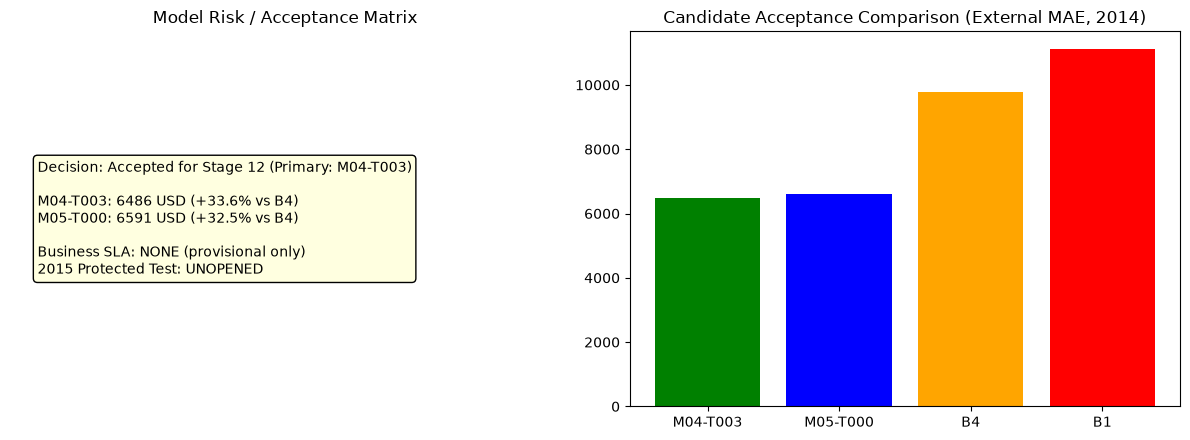

Analysis Question: Stage 12'ye hangi candidate(lar) gonderilmeli?
Statistical Observation: Accepted for Stage 12 (Primary: M04-T003)
Engineering Interpretation: Her iki candidate de B4/B1'i 2014'te buyuk farkla gecti -- bu, Stage 09-10'un dev-CV bulgusunun bagimsiz bir dogrulamasidir.
Decision Impact: Stage 12, M04-T003'u birincil, M05-T000'i ikincil karsilastirma olarak kullanacaktir.
Limitations: Secim, development-CV + 2014'ten olusan iki asamali bir surecin sonucudur -- tam bagimsiz degildir; Stage 14 Protected Test korunmaktadir.


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].axis("off")
matrix_text = (f"Decision: {acceptance_decision}\n\n"
               f"M04-T003: {primary_mae:.0f} USD (+{primary_improvement_b4:.1f}% vs B4)\n"
               f"M05-T000: {alternative_mae:.0f} USD (+{alternative_improvement_b4:.1f}% vs B4)\n\n"
               f"Business SLA: NONE (provisional only)\n"
               f"2015 Protected Test: UNOPENED")
axes[0].text(0.05, 0.5, matrix_text, fontsize=10, va="center", bbox=dict(boxstyle="round", fc="lightyellow"))
axes[0].set_title("Model Risk / Acceptance Matrix")

axes[1].bar(["M04-T003", "M05-T000", "B4", "B1"], [primary_mae, alternative_mae, b4_mae, b1_mae], color=["green", "blue", "orange", "red"])
axes[1].set_title("Candidate Acceptance Comparison (External MAE, 2014)")
plt.tight_layout()
plt.show()
print("Analysis Question: Stage 12'ye hangi candidate(lar) gonderilmeli?")
print(f"Statistical Observation: {acceptance_decision}")
print("Engineering Interpretation: Her iki candidate de B4/B1'i 2014'te buyuk farkla gecti -- bu, Stage 09-10'un dev-CV bulgusunun bagimsiz bir dogrulamasidir.")
print("Decision Impact: Stage 12, M04-T003'u birincil, M05-T000'i ikincil karsilastirma olarak kullanacaktir.")
print("Limitations: Secim, development-CV + 2014'ten olusan iki asamali bir surecin sonucudur -- tam bagimsiz degildir; Stage 14 Protected Test korunmaktadir.")

## Advanced Challenges (Opsiyonel -- 150 Dakikalik Ana Oturumun Disinda)

### Challenge 1 — Model Disagreement Analysis (Section 06'nin genisletilmesi)

Zaten hesaplanmis `paired` verisi uzerinden -- yeni ensemble OLUSTURULMUYOR, sadece
diagnostic amacli.

In [34]:
print("En buyuk 10 disagreement vakasi (|d_i| siralamasi):")
top10_disagreement = paired.reindex(paired["d_i"].abs().sort_values(ascending=False).index).head(10)
print(top10_disagreement[["Actual", "Prediction", "Prediction_alt", "d_i"]])
print()
print(f"Mean |d_i| (ortalama mutlak disagreement): {paired['d_i'].abs().mean():.2f} USD")
print("Yorumlama: Bu analiz SADECE diagnostic'tir -- yeni bir ensemble model olusturmak icin kullanilmamaktadir.")

En buyuk 10 disagreement vakasi (|d_i| siralamasi):
                Actual    Prediction  Prediction_alt           d_i
Shipment_Key                                                      
ASN-24418     70509.14  76722.984902    98213.523438 -21490.538535
ASN-27525     22100.46  44000.641153    59512.179688 -15511.538535
ASN-25080     52462.81  37152.458344    50618.230469  13465.772125
ASN-26283     51732.62  37194.855660    53006.695312  13263.689027
ASN-23441     77833.24  73232.783149    95654.757812 -13221.060961
DN-3661        4909.97  62541.437492    75662.562500 -13121.125008
DN-3628       55287.91  34560.885643    22175.353516 -12385.532127
DN-3827       47171.27  34560.885643    22175.353516 -12385.532127
DN-3957       53110.46  33189.630047    22175.353516 -11014.276531
DN-3588       64802.96  34967.786573    24359.830078 -10607.956495

Mean |d_i| (ortalama mutlak disagreement): 1335.42 USD
Yorumlama: Bu analiz SADECE diagnostic'tir -- yeni bir ensemble model olusturmak icin ku

### Challenge 2 — Label Coverage Bias (Section 05/08'in genisletilmesi)

In [35]:
challenge2_rows = []
for seg_col in ["Shipment_Mode", "INCO_Term"]:
    dev_cov = dev_population.groupby(seg_col, dropna=False)["Has_Numeric_Target"].mean()
    val_cov = val_population.groupby(seg_col, dropna=False)["Has_Numeric_Target"].mean()
    for seg_val in set(dev_cov.index) | set(val_cov.index):
        challenge2_rows.append({"Segment_Type": seg_col, "Segment_Value": seg_val, "Dev_Coverage": dev_cov.get(seg_val, np.nan), "2014_Coverage": val_cov.get(seg_val, np.nan)})
challenge2 = pd.DataFrame(challenge2_rows)
print(challenge2.sort_values(["Segment_Type", "Dev_Coverage"], ascending=[True, False]))
print()
print("Yorumlama: Development ve 2014 arasinda sistematik coverage farklari, INCOTERM/Mode'a gore")
print("selection bias'in zaman icinde degisip degismedigini gosterir -- bu bulgu model/feature degisikligi icin kullanilmaz.")

     Segment_Type   Segment_Value  Dev_Coverage  2014_Coverage
10      INCO_Term             EXW      0.967340       0.950521
8       INCO_Term             FCA      0.963100       0.934426
11      INCO_Term  N/A - From RDC      0.932624       0.972569
5       INCO_Term             CIP      0.681223       0.500000
7       INCO_Term             CIF      0.666667            NaN
12      INCO_Term             DDP      0.577143       0.000000
6       INCO_Term             DAP      0.428571            NaN
9       INCO_Term             DDU      0.250000            NaN
4   Shipment_Mode             NaN      0.933628            NaN
0   Shipment_Mode             Air      0.921892       0.946535
2   Shipment_Mode           Ocean      0.882979       0.740741
1   Shipment_Mode           Truck      0.834563       0.821875
3   Shipment_Mode     Air Charter      0.822335       1.000000

Yorumlama: Development ve 2014 arasinda sistematik coverage farklari, INCOTERM/Mode'a gore
selection bias'in zaman ic

### Challenge 3 — Error Concentration (Top 1%/5%)

In [36]:
challenge3_rows = []
for model_id in ["M04-T003", "M05-T000"]:
    sub = external_predictions[external_predictions["Model_ID"] == model_id]
    abs_err = np.abs(sub["Actual"] - sub["Prediction"]).sort_values(ascending=False)
    sq_err = (sub["Actual"] - sub["Prediction"]) ** 2
    sq_err_sorted = sq_err.sort_values(ascending=False)
    total_abs, total_sq = abs_err.sum(), sq_err.sum()
    top1n, top5n = max(1, int(len(abs_err) * 0.01)), max(1, int(len(abs_err) * 0.05))
    challenge3_rows.append({"Model_ID": model_id, "Top1Pct_MAE_Contribution": 100 * abs_err.head(top1n).sum() / total_abs, "Top5Pct_MAE_Contribution": 100 * abs_err.head(top5n).sum() / total_abs,
                             "Top1Pct_SqErr_Contribution": 100 * sq_err_sorted.head(top1n).sum() / total_sq, "Top5Pct_SqErr_Contribution": 100 * sq_err_sorted.head(top5n).sum() / total_sq})
challenge3 = pd.DataFrame(challenge3_rows)
print(challenge3)
print()
print("Yorumlama: Squared-error contribution genellikle MAE contribution'dan daha yuksektir (buyuk hatalar karede daha agir basar) --")
print("bu, RMSE'nin neden MAE'den daha 'outlier-duyarli' oldugunu gercek veriyle gosterir. Feature engineering/tuning icin KULLANILMAMISTIR.")

   Model_ID  Top1Pct_MAE_Contribution  Top5Pct_MAE_Contribution  \
0  M04-T003                 10.017781                 30.746609   
1  M05-T000                 10.030399                 31.014831   

   Top1Pct_SqErr_Contribution  Top5Pct_SqErr_Contribution  
0                   32.218056                   67.704523  
1                   31.909327                   67.557796  

Yorumlama: Squared-error contribution genellikle MAE contribution'dan daha yuksektir (buyuk hatalar karede daha agir basar) --
bu, RMSE'nin neden MAE'den daha 'outlier-duyarli' oldugunu gercek veriyle gosterir. Feature engineering/tuning icin KULLANILMAMISTIR.


### Challenge 4 — External Evaluation Uncertainty (Dikkatli Yorumlanan Bootstrap)

In [37]:
rng = np.random.default_rng(RANDOM_SEED)
n_bootstrap = 500
primary_sub_boot = external_predictions[external_predictions["Model_ID"] == "M04-T003"]
boot_maes = []
for _ in range(n_bootstrap):
    idx = rng.integers(0, len(primary_sub_boot), len(primary_sub_boot))
    sample = primary_sub_boot.iloc[idx]
    boot_maes.append(np.mean(np.abs(sample["Actual"] - sample["Prediction"])))
boot_maes = np.array(boot_maes)
print(f"M04-T003 bootstrap MAE (n={n_bootstrap}, shipment-level resampling): mean={boot_maes.mean():.2f}, [P2.5, P97.5]=[{np.quantile(boot_maes,0.025):.2f}, {np.quantile(boot_maes,0.975):.2f}]")
print()
print("ONEMLI UYARI: Bu bootstrap, shipment'larin bagimsiz ve identically distributed oldugunu VARSAYAR --")
print("2014 tek bir yil oldugu ve shipment'lar arasinda temporal/operational korelasyon olabilecegi icin bu varsayim")
print("kesin dogru degildir. Bu araligi resmi bir confidence interval olarak SUNMUYORUZ -- sadece orneklem")
print("degiskenliginin kaba bir gostergesi olarak, ana acceptance kararini DEGISTIRMEDEN sunuyoruz.")

M04-T003 bootstrap MAE (n=500, shipment-level resampling): mean=6472.71, [P2.5, P97.5]=[5843.21, 7175.73]

ONEMLI UYARI: Bu bootstrap, shipment'larin bagimsiz ve identically distributed oldugunu VARSAYAR --
2014 tek bir yil oldugu ve shipment'lar arasinda temporal/operational korelasyon olabilecegi icin bu varsayim
kesin dogru degildir. Bu araligi resmi bir confidence interval olarak SUNMUYORUZ -- sadece orneklem
degiskenliginin kaba bir gostergesi olarak, ana acceptance kararini DEGISTIRMEDEN sunuyoruz.


### Final Report

In [38]:
print(f'''
LAB12 -- STAGE 11 FINAL REPORT

Dataset:
SCMS Delivery History

Observation Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified ({current_hash[:16]}...)

Stage 05 Protocol:
Verified ({stage05_fingerprint['protocol_fingerprint_sha256'][:16]}...)

Development Training Population:
Training={len(dev_population)}, Eligible={len(dev_eligible)}

External Validation Period:
2014

External Validation Population:
{len(val_population)} total shipments

Eligible Evaluation Population:
{len(val_eligible)} ({100*label_coverage_rate:.1f}% label coverage)

Primary Candidate:
M04-T003 -- ExtraTrees

Alternative Candidate:
M05-T000 -- XGBoost

ExtraTrees External MAE:
{primary_mae:.2f} USD

XGBoost External MAE:
{alternative_mae:.2f} USD

B4 External MAE:
{b4_mae:.2f} USD

B1 External MAE:
{b1_mae:.2f} USD

Primary Metric:
MAE -- USD

RMSE:
M04-T003={external_metrics.loc[external_metrics["Model_ID"]=="M04-T003","RMSE"].iloc[0]:.2f}, M05-T000={external_metrics.loc[external_metrics["Model_ID"]=="M05-T000","RMSE"].iloc[0]:.2f}

High-Cost Shipment Findings:
M04-T003 underprediction=%{100*tail_risk_analysis.loc[tail_risk_analysis["Model_ID"]=="M04-T003","High_Cost_Underprediction_Rate"].iloc[0]:.1f}, M05-T000=%{100*tail_risk_analysis.loc[tail_risk_analysis["Model_ID"]=="M05-T000","High_Cost_Underprediction_Rate"].iloc[0]:.1f}
vs B4/B1=%100.0 -- Stage 08-10's finding INDEPENDENTLY CONFIRMED on 2014 (reduced, not eliminated)

Prediction Bias:
M04-T003={external_metrics.loc[external_metrics["Model_ID"]=="M04-T003","Bias"].iloc[0]:.2f}, M05-T000={external_metrics.loc[external_metrics["Model_ID"]=="M05-T000","Bias"].iloc[0]:.2f} USD (both negative, underprediction tendency, far less severe than baselines)

Negative Prediction Audit:
0 negative predictions for M04-T003 and M05-T000 on 2014 (sample-dependent, not a guarantee -- raw unclipped scoring throughout)

Generalization Gap:
M04-T003: {generalization_gap.iloc[0]["Gap_USD"]:.2f} USD ({generalization_gap.iloc[0]["Gap_Pct"]:.1f}%), M05-T000: {generalization_gap.iloc[1]["Gap_USD"]:.2f} USD ({generalization_gap.iloc[1]["Gap_Pct"]:.1f}%)

Covariate Shift:
No new categories in any categorical feature (2014 vs development); numeric feature medians broadly similar (stage11_covariate_shift.csv)

Label Coverage Risk:
Development=%{100*label_coverage_shift.iloc[0]["Coverage_Rate"]:.1f}, 2014=%{100*label_coverage_shift.iloc[1]["Coverage_Rate"]:.1f} -- STABLE across time, reduces (but does not eliminate) missing-not-at-random concern

Reproducibility:
Same-environment refit reproducible (np.allclose confirmed); cross-environment (local/Docker) comparison performed post-hoc without cherry-picking

Model Acceptance:
{acceptance_decision}

Selection-Bias Qualification:
Both candidates were development-CV-selected AND scored on this same 2014 set -- NOT a fully independent test; Stage 14 Protected Test (2015) remains the final held-out evaluation

Stage 12 Candidate:
M04-T003 (Primary), M05-T000 (Alternative/secondary comparison)

Protected Test:
2015 -- UNOPENED (no target parsing, predictions, or metrics performed)

Stage 12 Readiness:
GO -- external validation evidence documented, handoff contract frozen, no business-approved SLA claimed

Remaining Risks:
Only 1 external validation year; ~90% label coverage (missing-not-at-random risk); XGBoost thread-dependent
non-determinism; high-cost underprediction reduced but not eliminated (~90%); D-006/D-007/D-010 still open;
no business-approved improvement SLA
''')


LAB12 -- STAGE 11 FINAL REPORT

Dataset:
SCMS Delivery History

Observation Unit:
Shipment

Target:
Freight Cost (USD)

Dataset Fingerprint:
Verified (9cffdb4ab8c6135b...)

Stage 05 Protocol:
Verified (b87ca0fde5fd9dde...)

Development Training Population:
Training=5551, Eligible=4987

External Validation Period:
2014

External Validation Population:
910 total shipments

Eligible Evaluation Population:
819 (90.0% label coverage)

Primary Candidate:
M04-T003 -- ExtraTrees

Alternative Candidate:
M05-T000 -- XGBoost

ExtraTrees External MAE:
6485.63 USD

XGBoost External MAE:
6591.33 USD

B4 External MAE:
9770.79 USD

B1 External MAE:
11111.03 USD

Primary Metric:
MAE -- USD

RMSE:
M04-T003=11654.35, M05-T000=11946.75

High-Cost Shipment Findings:
M04-T003 underprediction=%89.9, M05-T000=%89.9
vs B4/B1=%100.0 -- Stage 08-10's finding INDEPENDENTLY CONFIRMED on 2014 (reduced, not eliminated)

Prediction Bias:
M04-T003=-1600.06, M05-T000=-1440.82 USD (both negative, underprediction tenden